# 02 — MLPs preliminares (MLP-A-128 e MLP-B-128)

Experimento 1 (fase de acompanhamento): imagens RGB 128 × 128 convertidas em vetor, duas MLPs de estrutura diferente, treino com monitoramento de **F1 macro na validação**, checkpoint, histórico e curvas. Tudo é definido neste notebook, sem depender de código em `src/`.

> O **teste não é usado** aqui (regra do acompanhamento). As execuções são identificadas como `preliminar`, separadas das seis execuções finais.

Pré-requisitos: `dados/raw/NWPU-RESISC45/` com as 10 classes e `dados/splits/particoes.csv` já gerado.

## 1. Imports, configuração e semente

In [3]:
import json
import os
import platform
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, f1_score, precision_score, recall_score
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CLASSES = ("airport", "beach", "circular_farmland", "dense_residential", "desert",
           "forest", "harbor", "mountain", "river", "storage_tank")  # ordem fixa do projeto

RESOLUCAO = 128
SEMENTE = 42
LR, WEIGHT_DECAY, LOTE, MAX_EPOCAS, PACIENCIA = 1e-4, 1e-4, 64, 200, 10


def fixar_semente():
    random.seed(SEMENTE)
    np.random.seed(SEMENTE)
    torch.manual_seed(SEMENTE)
    torch.cuda.manual_seed_all(SEMENTE)
    os.environ["PYTHONHASHSEED"] = str(SEMENTE)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


fixar_semente()

if torch.cuda.is_available():
    dispositivo, hardware = torch.device("cuda"), f"GPU {torch.cuda.get_device_name(0)}"
elif torch.backends.mps.is_available():
    dispositivo, hardware = torch.device("mps"), "Apple MPS"
else:
    dispositivo, hardware = torch.device("cpu"), f"CPU {platform.processor() or platform.machine()} ({os.cpu_count()} núcleos lógicos)"
print("torch", torch.__version__, "|", hardware)

torch 2.15.0 | Apple MPS


## 2. Imagem → vetor

Cada imagem é lida do **original**, convertida para RGB, redimensionada (bilinear) para 128 × 128, dividida por 255 e padronizada por canal com média e desvio **calculados só no treino** e reaplicados à validação. Depois o tensor `(3, 128, 128)` é achatado em um vetor de **49.152** valores. Só treino e validação são carregados.

In [4]:
particoes = pd.read_csv(RAIZ / "dados" / "splits" / "particoes.csv").sort_values("caminho_relativo")
particoes["rotulo"] = particoes["classe"].map({c: i for i, c in enumerate(CLASSES)})


def carregar(particao):
    sub = particoes[particoes["particao"] == particao]
    imagens = []
    for caminho in sub["caminho_relativo"]:
        with Image.open(RAIZ / caminho) as img:
            imagens.append(np.asarray(img.convert("RGB").resize((RESOLUCAO, RESOLUCAO), Image.BILINEAR), dtype=np.uint8))
    return np.stack(imagens), sub["rotulo"].to_numpy(np.int64)


img_tr, y_tr = carregar("treino")
img_va, y_va = carregar("validacao")

# estatísticas apenas do treino (em blocos, para não alocar o treino inteiro em float64)
media = img_tr.reshape(-1, 3).mean(0, dtype=np.float64) / 255
desvio = np.sqrt(sum(((img_tr[i:i + 256].reshape(-1, 3) / 255.0 - media) ** 2).sum(0)
                     for i in range(0, len(img_tr), 256)) / (img_tr.size / 3))


def para_vetor(imagens):
    x = (imagens.astype(np.float32) / 255.0 - media.astype(np.float32)) / desvio.astype(np.float32)
    return np.ascontiguousarray(x.transpose(0, 3, 1, 2)).reshape(len(imagens), -1)  # (N, 3*128*128)


X_tr, X_va = para_vetor(img_tr), para_vetor(img_va)
print("Treino   :", X_tr.shape, X_tr.dtype)
print("Validação:", X_va.shape)
print("Média por canal (treino) :", np.round(media, 4))
print("Desvio por canal (treino):", np.round(desvio, 4))
print(pd.Series(y_tr).map(dict(enumerate(CLASSES))).value_counts().reindex(CLASSES))

Treino   : (4899, 49152) float32
Validação: (1050, 49152)
Média por canal (treino) : [0.4009 0.4073 0.3541]
Desvio por canal (treino): [0.2235 0.186  0.1724]
airport              489
beach                490
circular_farmland    490
dense_residential    490
desert               490
forest               490
harbor               490
mountain             490
river                490
storage_tank         490
Name: count, dtype: int64


Verificação: desfazer o achatamento de um vetor deve reproduzir a imagem.

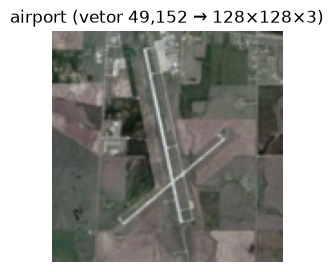

In [5]:
i = 0
vol = X_tr[i].reshape(3, RESOLUCAO, RESOLUCAO).transpose(1, 2, 0) * desvio + media
plt.figure(figsize=(3, 3)); plt.imshow(np.clip(vol, 0, 1)); plt.axis("off")
plt.title(f"{CLASSES[y_tr[i]]} (vetor {X_tr.shape[1]:,} → {RESOLUCAO}×{RESOLUCAO}×3)"); plt.show()

## 3. Arquiteturas

Hipótese: com pixels achatados a MLP perde a estrutura espacial. Mais profundidade poderia compor padrões mais abstratos de cor e textura, mas aumenta o risco de sobreajuste com apenas 4.899 imagens de treino. Quase todos os parâmetros estão na primeira camada (49.152 × 512), então A e B têm custo parecido e a diferença isola o efeito da **profundidade**.

| Classe | Camadas ocultas | Entrada → saída |
|---|---|---|
| `MLPA` (rasa) | 512 → 128 | 49.152 → 10 |
| `MLPB` (profunda) | 512 → 256 → 128 → 64 | 49.152 → 10 |

Cada camada oculta é Linear → BatchNorm → ReLU → Dropout(0,5). A saída são logits (o softmax está na perda). As duas classes são independentes, e o código se repete de propósito.

In [12]:
class MLPA(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.rede = nn.Sequential(
            nn.Linear(3 * RESOLUCAO * RESOLUCAO, 512), nn.BatchNorm1d(512), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(512, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(128, n_classes))

    def forward(self, x):
        return self.rede(x.flatten(1))


class MLPB(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.rede = nn.Sequential(
            nn.Linear(3 * RESOLUCAO * RESOLUCAO, 512), nn.BatchNorm1d(512), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(512, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(256, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(128, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(64, n_classes))

    def forward(self, x):
        return self.rede(x.flatten(1))


for Modelo in (MLPA, MLPB):
    m = Modelo()
    print(Modelo.__name__, f"{sum(p.numel() for p in m.parameters()):,} parâmetros", m(torch.randn(2, 3, RESOLUCAO, RESOLUCAO)).shape)

MLPA 25,234,570 parâmetros torch.Size([2, 10])
MLPB 25,341,386 parâmetros torch.Size([2, 10])


## 4. Protocolo de treino

| Item | Valor |
|---|---|
| Perda | CrossEntropyLoss |
| Otimizador | Adam, lr = 1e-4, weight decay = 1e-4 |
| Lote | 64 |
| Limite de épocas | 200 (quem encerra o treino é a parada antecipada) |
| Parada | 10 épocas sem melhora no **F1 macro de validação** |
| Checkpoint | época de maior F1 macro de validação |
| Aumento de dados | nenhum no 1º treino. 2º treino: espelhamentos e rotações de 90°. 3º treino: o anterior mais zoom, cor e apagamento. Sempre só no treino |
| Métricas por época | perda, acurácia, precisão, recall e F1 (macro), em treino e validação |
| Relatório por classe | precisão, recall, F1 e suporte na validação, no checkpoint. Classe sem previsões recebe precisão 0 (`zero_division=0`) |
| Semente | 42 |

A função `treinar` (com `aumento=False`, `True` ou `"forte"`) treina do zero, salva o melhor checkpoint em `modelos/`, o histórico em `resultados/historicos/`, a configuração em `resultados/configs/` e uma linha em `resultados/experimentos.csv`. O tempo mede só o laço de treino e validação de cada época, sem a leitura das imagens.

In [6]:
def aumentar(x, g):
    """Aumento de dados (só no treino): espelhamentos e rotações de 90°, sorteados por imagem."""
    n = len(x)
    h = (torch.rand(n, generator=g) < 0.5).to(x.device)[:, None, None, None]
    v = (torch.rand(n, generator=g) < 0.5).to(x.device)[:, None, None, None]
    k = torch.randint(0, 4, (n,), generator=g).to(x.device)[:, None, None, None]
    x = torch.where(h, x.flip(3), x)
    x = torch.where(v, x.flip(2), x)
    for q in (1, 2, 3):
        x = torch.where(k == q, torch.rot90(x, q, (2, 3)), x)
    return x


media_t = torch.tensor(media, dtype=torch.float32, device=dispositivo).view(1, 3, 1, 1)
desvio_t = torch.tensor(desvio, dtype=torch.float32, device=dispositivo).view(1, 3, 1, 1)


def aumentar_forte(x, g):
    # Aumento mais agressivo (só no treino), aplicado depois de espelhamentos e rotações:
    # 1) recorte com zoom, 2) variação de cor, 3) apagamento aleatório de um retângulo.
    n, _, R, _ = x.shape
    d = x.device
    u = lambda lo, hi: (lo + (hi - lo) * torch.rand(n, generator=g)).to(d)

    # 1) recorte com zoom: 50 a 100% da área, posição aleatória, reescalado para R x R
    f = u(0.5, 1.0).sqrt()
    tx = (2 * torch.rand(n, generator=g) - 1).to(d) * (1 - f)
    ty = (2 * torch.rand(n, generator=g) - 1).to(d) * (1 - f)
    zero = torch.zeros(n, device=d)
    theta = torch.stack([torch.stack([f, zero, tx], 1), torch.stack([zero, f, ty], 1)], 1)
    grade = nn.functional.affine_grid(theta, list(x.shape), align_corners=False)
    x = nn.functional.grid_sample(x, grade, mode="bilinear", padding_mode="reflection", align_corners=False)

    # 2) cor (brilho, contraste e saturação, cada um entre 80% e 120%), calculada em escala [0, 1]
    pix = x * desvio_t + media_t
    pix = pix * u(0.8, 1.2)[:, None, None, None]
    cinza = pix.mean((1, 2, 3), keepdim=True)
    pix = (pix - cinza) * u(0.8, 1.2)[:, None, None, None] + cinza
    cinza_px = pix.mean(1, keepdim=True)
    pix = (pix - cinza_px) * u(0.8, 1.2)[:, None, None, None] + cinza_px
    x = (pix.clamp(0, 1) - media_t) / desvio_t

    # 3) apagamento aleatório: com 50% de chance, um retângulo (10 a 40% do lado) vira o valor médio
    hh = (R * u(0.1, 0.4)).long()[:, None, None]
    ww = (R * u(0.1, 0.4)).long()[:, None, None]
    y0 = ((R - hh) * torch.rand(n, 1, 1, generator=g).to(d)).long()
    x0 = ((R - ww) * torch.rand(n, 1, 1, generator=g).to(d)).long()
    ys, xs = torch.arange(R, device=d)[None, :, None], torch.arange(R, device=d)[None, None, :]
    caixa = (ys >= y0) & (ys < y0 + hh) & (xs >= x0) & (xs < x0 + ww) & (torch.rand(n, 1, 1, generator=g).to(d) < 0.5)
    return x.masked_fill(caixa[:, None], 0.0)


def treinar(modelo, nome, aumento=False):
    # aumento: False (nenhum), True (espelhamentos e rotações de 90°) ou "forte" (acrescenta zoom, cor e apagamento)
    descricao_aumento = {
        False: "nenhum",
        True: "espelhamentos e rotações de 90° (só no treino)",
        "forte": "espelhamentos e rotações de 90°, recorte com zoom (50-100% da área), variação de cor (brilho, contraste e saturação ±20%) "
                 "e apagamento aleatório (p = 0,5; 10-40% do lado), só no treino",
    }[aumento]
    extras = {"arquitetura": nome, "classe": type(modelo).__name__, "aumento_de_dados": descricao_aumento}
    nome_execucao = nome + "_preliminar"
    gerador_aug = torch.Generator().manual_seed(SEMENTE)
    modelo = modelo.to(dispositivo)
    perda_fn = nn.CrossEntropyLoss()
    otimizador = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    loader_tr = DataLoader(TensorDataset(torch.from_numpy(X_tr), torch.from_numpy(y_tr)), batch_size=LOTE,
                           shuffle=True, generator=torch.Generator().manual_seed(SEMENTE))
    loader_va = DataLoader(TensorDataset(torch.from_numpy(X_va), torch.from_numpy(y_va)), batch_size=LOTE)

    def epoca(loader, treino):
        modelo.train(treino)
        soma, previstas, reais = 0.0, [], []
        with torch.set_grad_enabled(treino):
            for xb, yb in loader:
                xb, yb = xb.to(dispositivo), yb.to(dispositivo)
                if treino and aumento:
                    xb = aumentar(xb.view(-1, 3, RESOLUCAO, RESOLUCAO), gerador_aug)
                    if aumento == "forte":
                        xb = aumentar_forte(xb, gerador_aug)
                logits = modelo(xb)
                perda = perda_fn(logits, yb)
                if treino:
                    otimizador.zero_grad(set_to_none=True)
                    perda.backward()
                    otimizador.step()
                soma += perda.item() * len(yb)
                previstas.append(logits.argmax(1).cpu())
                reais.append(yb.cpu())
        p, r = torch.cat(previstas).numpy(), torch.cat(reais).numpy()
        macro = dict(average="macro", zero_division=0)  # classe sem previsões: precisão = 0 (sem divisão por zero)
        return (soma / len(r), accuracy_score(r, p), precision_score(r, p, **macro),
                recall_score(r, p, **macro), f1_score(r, p, **macro))

    (RAIZ / "modelos").mkdir(exist_ok=True)
    caminho_ckpt = RAIZ / "modelos" / f"{nome_execucao}.pt"
    historico, melhor_f1, melhor_epoca, sem_melhora, tempo_total = [], -1.0, 0, 0, 0.0

    for n in range(1, MAX_EPOCAS + 1):
        if dispositivo.type == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter()
        tr = epoca(loader_tr, True)
        va = epoca(loader_va, False)
        if dispositivo.type == "cuda": torch.cuda.synchronize()
        dt = time.perf_counter() - t0
        tempo_total += dt
        historico.append({"epoca": n,
                          "perda_treino": tr[0], "acuracia_treino": tr[1], "precisao_macro_treino": tr[2],
                          "recall_macro_treino": tr[3], "f1_macro_treino": tr[4],
                          "perda_validacao": va[0], "acuracia_validacao": va[1], "precisao_macro_validacao": va[2],
                          "recall_macro_validacao": va[3], "f1_macro_validacao": va[4], "tempo_epoca_s": dt})
        melhorou = va[4] > melhor_f1
        if melhorou:
            melhor_f1, melhor_epoca, sem_melhora = va[4], n, 0
            torch.save({"state_dict": modelo.state_dict(), "epoca": n, "f1_macro_validacao": va[4]}, caminho_ckpt)
        else:
            sem_melhora += 1
        print(f"[{nome_execucao}] época {n:3d}/{MAX_EPOCAS} | "
              f"treino: perda {tr[0]:.4f} acc {tr[1]:.4f} P {tr[2]:.4f} R {tr[3]:.4f} F1 {tr[4]:.4f} | "
              f"val: perda {va[0]:.4f} acc {va[1]:.4f} P {va[2]:.4f} R {va[3]:.4f} F1 {va[4]:.4f} | {dt:5.1f}s"
              + ("  *checkpoint*" if melhorou else ""))
        if sem_melhora >= PACIENCIA:
            print(f"Parada antecipada: {PACIENCIA} épocas sem melhora no F1 macro de validação.")
            break

    hist = pd.DataFrame(historico)
    hist["checkpoint"] = hist["epoca"] == melhor_epoca
    (RAIZ / "resultados" / "historicos").mkdir(parents=True, exist_ok=True)
    hist.to_csv(RAIZ / "resultados" / "historicos" / f"{nome_execucao}_historico.csv", index=False)

    ck = hist[hist["checkpoint"]].iloc[0]
    resumo = {
        "nome_execucao": nome_execucao, "tipo_execucao": "preliminar",
        "parametros": sum(p.numel() for p in modelo.parameters()),
        "tamanho_modelo_mb": round(caminho_ckpt.stat().st_size / 1024**2, 2),
        "epocas_executadas": len(hist), "epoca_checkpoint": melhor_epoca,
        "f1_macro_validacao": round(float(ck["f1_macro_validacao"]), 4),
        "acuracia_validacao": round(float(ck["acuracia_validacao"]), 4),
        "perda_validacao": round(float(ck["perda_validacao"]), 4),
        "tempo_total_s": round(tempo_total, 1), "tempo_medio_epoca_s": round(tempo_total / len(hist), 2),
        "hardware": hardware, "otimizador": "adam", "taxa_aprendizagem": LR, "weight_decay": WEIGHT_DECAY,
        "tamanho_lote": LOTE, "max_epocas": MAX_EPOCAS, "paciencia": PACIENCIA,
        "criterio_parada": "F1 macro de validação", "semente": SEMENTE, "torch": torch.__version__,
        "extras": json.dumps(extras, ensure_ascii=False),
    }
    print(f"\nResumo {nome_execucao}: checkpoint na época {melhor_epoca} de {len(hist)} | {resumo['parametros']:,} parâmetros | "
          f"{tempo_total:.1f}s no total ({tempo_total / len(hist):.2f}s/época)")
    for rotulo, sufixo in (("treino   ", "treino"), ("validação", "validacao")):
        print(f"  {rotulo} : perda {ck['perda_' + sufixo]:.4f} | acurácia {ck['acuracia_' + sufixo]:.4f} | "
              f"precisão macro {ck['precisao_macro_' + sufixo]:.4f} | recall macro {ck['recall_macro_' + sufixo]:.4f} | "
              f"F1 macro {ck['f1_macro_' + sufixo]:.4f}")
    print(f"  diferença treino − validação (F1 macro): {ck['f1_macro_treino'] - ck['f1_macro_validacao']:+.4f}")
    modelo.load_state_dict(torch.load(caminho_ckpt, map_location=dispositivo)["state_dict"])
    modelo.eval()
    with torch.no_grad():
        previstas = torch.cat([modelo(xb.to(dispositivo)).argmax(1).cpu() for xb, _ in loader_va]).numpy()
    print(f"\nRelatório por classe (validação, checkpoint da época {melhor_epoca}):")
    print(classification_report(y_va, previstas, target_names=CLASSES, digits=4, zero_division=0))
    csv_exp = RAIZ / "resultados" / "experimentos.csv"
    novo = pd.DataFrame([resumo])
    if csv_exp.is_file():
        antigo = pd.read_csv(csv_exp)
        novo = pd.concat([antigo[antigo["nome_execucao"] != nome_execucao], novo], ignore_index=True)
    novo.to_csv(csv_exp, index=False)

    (RAIZ / "resultados" / "configs").mkdir(parents=True, exist_ok=True)
    with open(RAIZ / "resultados" / "configs" / f"{nome_execucao}.json", "w", encoding="utf-8") as f:
        json.dump({"arquitetura": nome, "entrada": f"RGB {RESOLUCAO}x{RESOLUCAO} achatado ({X_tr.shape[1]} valores)",
                   "classes": list(CLASSES), "normalizacao": {"media": media.tolist(), "desvio": desvio.tolist()},
                   "aumento_de_dados": descricao_aumento, "perda": "CrossEntropyLoss", "resultado": resumo}, f, indent=2, ensure_ascii=False)
    return resumo, hist


def plotar_curvas(hist, nome):
    ep = int(hist.loc[hist["checkpoint"], "epoca"].iloc[0])
    fig, eixos = plt.subplots(1, 3, figsize=(15, 4.2))
    for ax, (chave, titulo) in zip(eixos, [("perda", "Perda (entropia cruzada)"), ("acuracia", "Acurácia"), ("f1_macro", "F1 macro")]):
        ax.plot(hist["epoca"], hist[f"{chave}_treino"], color="#2a78b5", lw=2, label="Treino")
        ax.plot(hist["epoca"], hist[f"{chave}_validacao"], color="#d9762b", lw=2, label="Validação")
        ax.axvline(ep, color="#555", ls="--", lw=1)
        ax.scatter([ep], [hist.loc[hist["epoca"] == ep, f"{chave}_validacao"].iloc[0]], color="#d9762b", zorder=3, s=40)
        ax.set_title(titulo); ax.set_xlabel("Época"); ax.grid(alpha=0.25)
    eixos[0].legend(frameon=False)
    fig.suptitle(f"{nome} — curvas de aprendizagem (checkpoint na época {ep})", fontweight="bold")
    fig.text(0.01, 0.01, "Fonte: elaborado pelos autores (NWPU-RESISC45, 10 classes).", fontsize=8, color="#666")
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    (RAIZ / "resultados" / "figuras" / "mlp").mkdir(parents=True, exist_ok=True)
    fig.savefig(RAIZ / "resultados" / "figuras" / "mlp" / f"{nome}_preliminar_curvas.png", dpi=150)
    plt.show()

## 5. Treino da MLP-A

In [21]:
resumo_a, hist_a = treinar(MLPA(), "MLP-A-128")
pd.Series(resumo_a)

[MLP-A-128_preliminar] época   1/200 | treino: perda 1.9930 acc 0.2935 P 0.2493 R 0.2935 F1 0.2535 | val: perda 1.7724 acc 0.4038 P 0.3740 R 0.4038 F1 0.3238 |   1.9s  *checkpoint*
[MLP-A-128_preliminar] época   2/200 | treino: perda 1.7681 acc 0.4115 P 0.3808 R 0.4115 F1 0.3735 | val: perda 1.6603 acc 0.4695 P 0.4458 R 0.4695 F1 0.4163 |   1.9s  *checkpoint*
[MLP-A-128_preliminar] época   3/200 | treino: perda 1.6427 acc 0.4664 P 0.4446 R 0.4664 F1 0.4377 | val: perda 1.5754 acc 0.4867 P 0.4605 R 0.4867 F1 0.4445 |   1.8s  *checkpoint*
[MLP-A-128_preliminar] época   4/200 | treino: perda 1.5547 acc 0.4987 P 0.4749 R 0.4986 F1 0.4754 | val: perda 1.5174 acc 0.5162 P 0.4867 R 0.5162 F1 0.4855 |   1.8s  *checkpoint*
[MLP-A-128_preliminar] época   5/200 | treino: perda 1.4894 acc 0.5213 P 0.4987 R 0.5213 F1 0.5004 | val: perda 1.4520 acc 0.5295 P 0.5072 R 0.5295 F1 0.5034 |   1.9s  *checkpoint*
[MLP-A-128_preliminar] época   6/200 | treino: perda 1.4187 acc 0.5573 P 0.5419 R 0.5572 F1 0.5

nome_execucao                                       MLP-A-128_preliminar
tipo_execucao                                                 preliminar
parametros                                                      25234570
tamanho_modelo_mb                                                  96.27
epocas_executadas                                                     29
epoca_checkpoint                                                      19
f1_macro_validacao                                                0.5359
acuracia_validacao                                                0.5448
perda_validacao                                                   1.3266
tempo_total_s                                                       53.6
tempo_medio_epoca_s                                                 1.85
hardware                                                       Apple MPS
otimizador                                                          adam
taxa_aprendizagem                                  

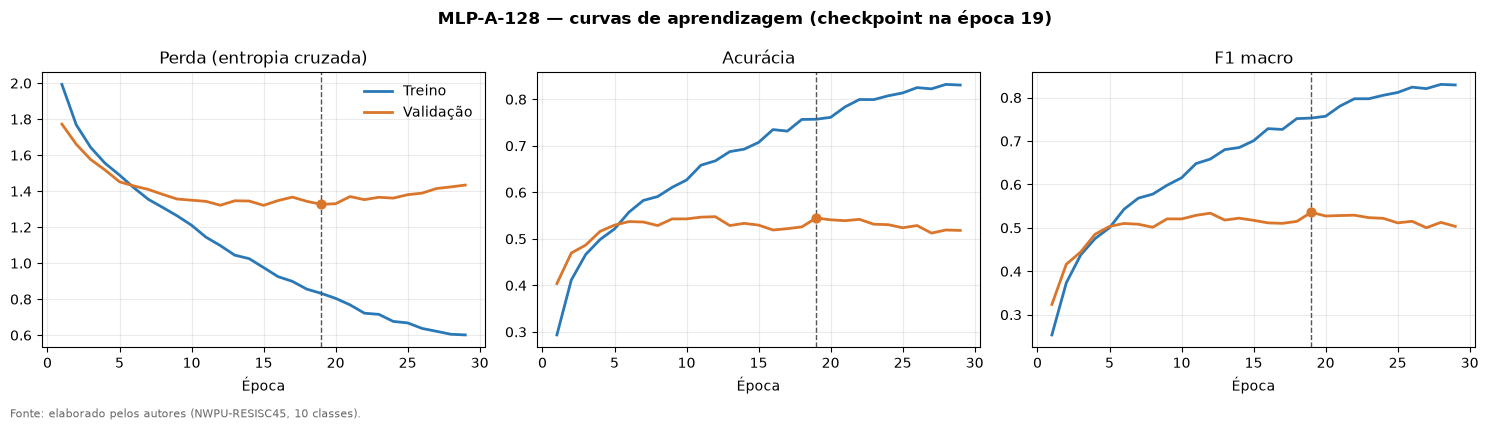

,epoca,perda_treino,acuracia_treino,precisao_macro_treino,recall_macro_treino,f1_macro_treino,perda_validacao,acuracia_validacao,precisao_macro_validacao,recall_macro_validacao,f1_macro_validacao,tempo_epoca_s,checkpoint
0,1,1.9930,0.2935,0.2493,0.2935,0.2535,1.7724,0.4038,0.3740,0.4038,0.3238,1.9404,False
1,2,1.7681,0.4115,0.3808,0.4115,0.3735,1.6603,0.4695,0.4458,0.4695,0.4163,1.8536,False
2,3,1.6427,0.4664,0.4446,0.4664,0.4377,1.5754,0.4867,0.4605,0.4867,0.4445,1.8444,False
3,4,1.5547,0.4987,0.4749,0.4986,0.4754,1.5174,0.5162,0.4867,0.5162,0.4855,1.8444,False
4,5,1.4894,0.5213,0.4987,0.5213,0.5004,1.4520,0.5295,0.5072,0.5295,0.5034,1.8652,False
5,6,1.4187,0.5573,0.5419,0.5572,0.5428,1.4287,0.5371,0.5072,0.5371,0.5102,1.8525,False
6,7,1.3545,0.5826,0.5674,0.5825,0.5685,1.4097,0.5362,0.5065,0.5362,0.5084,1.8454,False
7,8,1.3094,0.5909,0.5765,0.5909,0.5777,1.3819,0.5286,0.5049,0.5286,0.5015,1.8377,False
8,9,1.2629,0.6107,0.5961,0.6107,0.5983,1.3563,0.5429,0.5156,0.5429,0.5207,1.8492,False
9,10,1.2108,0.6265,0.6132,0.6264,0.6154,1.3498,0.5429,0.5156,0.5429,0.5206,1.8616,False


In [22]:
plotar_curvas(hist_a, "MLP-A-128")
hist_a.round(4)

## 6. Treino da MLP-B

In [23]:
resumo_b, hist_b = treinar(MLPB(), "MLP-B-128")
pd.Series(resumo_b)

[MLP-B-128_preliminar] época   1/200 | treino: perda 2.3446 acc 0.1247 P 0.1531 R 0.1247 F1 0.1216 | val: perda 2.1576 acc 0.2914 P 0.3712 R 0.2914 F1 0.2378 |   2.0s  *checkpoint*
[MLP-B-128_preliminar] época   2/200 | treino: perda 2.2119 acc 0.1790 P 0.1952 R 0.1790 F1 0.1766 | val: perda 2.0574 acc 0.3248 P 0.4026 R 0.3248 F1 0.2627 |   1.9s  *checkpoint*
[MLP-B-128_preliminar] época   3/200 | treino: perda 2.1106 acc 0.2337 P 0.2270 R 0.2337 F1 0.2240 | val: perda 1.9904 acc 0.3524 P 0.4022 R 0.3524 F1 0.2973 |   1.9s  *checkpoint*
[MLP-B-128_preliminar] época   4/200 | treino: perda 2.0337 acc 0.2805 P 0.2602 R 0.2804 F1 0.2640 | val: perda 1.9281 acc 0.3810 P 0.3712 R 0.3810 F1 0.3199 |   1.9s  *checkpoint*
[MLP-B-128_preliminar] época   5/200 | treino: perda 2.0011 acc 0.3029 P 0.2704 R 0.3029 F1 0.2784 | val: perda 1.8768 acc 0.4057 P 0.4558 R 0.4057 F1 0.3501 |   1.9s  *checkpoint*
[MLP-B-128_preliminar] época   6/200 | treino: perda 1.9662 acc 0.3154 P 0.2822 R 0.3153 F1 0.2

nome_execucao                                       MLP-B-128_preliminar
tipo_execucao                                                 preliminar
parametros                                                      25341386
tamanho_modelo_mb                                                  96.69
epocas_executadas                                                     51
epoca_checkpoint                                                      41
f1_macro_validacao                                                0.5353
acuracia_validacao                                                0.5419
perda_validacao                                                   1.3718
tempo_total_s                                                       99.5
tempo_medio_epoca_s                                                 1.95
hardware                                                       Apple MPS
otimizador                                                          adam
taxa_aprendizagem                                  

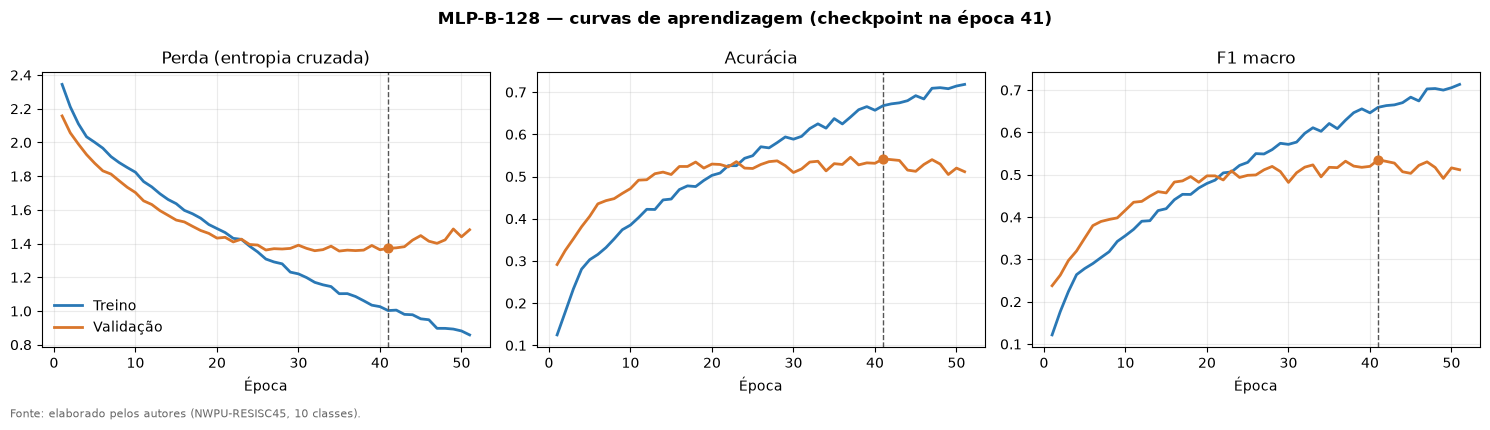

,epoca,perda_treino,acuracia_treino,precisao_macro_treino,recall_macro_treino,f1_macro_treino,perda_validacao,acuracia_validacao,precisao_macro_validacao,recall_macro_validacao,f1_macro_validacao,tempo_epoca_s,checkpoint
0,1,2.3446,0.1247,0.1531,0.1247,0.1216,2.1576,0.2914,0.3712,0.2914,0.2378,1.9687,False
1,2,2.2119,0.1790,0.1952,0.1790,0.1766,2.0574,0.3248,0.4026,0.3248,0.2627,1.8880,False
2,3,2.1106,0.2337,0.2270,0.2337,0.2240,1.9904,0.3524,0.4022,0.3524,0.2973,1.8807,False
3,4,2.0337,0.2805,0.2602,0.2804,0.2640,1.9281,0.3810,0.3712,0.3810,0.3199,1.9100,False
4,5,2.0011,0.3029,0.2704,0.3029,0.2784,1.8768,0.4057,0.4558,0.4057,0.3501,1.8817,False
5,6,1.9662,0.3154,0.2822,0.3153,0.2902,1.8316,0.4352,0.4320,0.4352,0.3798,1.9190,False
6,7,1.9161,0.3317,0.2946,0.3317,0.3043,1.8125,0.4429,0.4166,0.4429,0.3896,1.8674,False
7,8,1.8808,0.3521,0.3090,0.3521,0.3181,1.7727,0.4476,0.4146,0.4476,0.3943,1.8804,False
8,9,1.8512,0.3740,0.3368,0.3739,0.3425,1.7340,0.4600,0.4350,0.4600,0.3981,1.9231,False
9,10,1.8235,0.3850,0.3495,0.3849,0.3561,1.7028,0.4714,0.4430,0.4714,0.4164,1.8749,False


In [24]:
plotar_curvas(hist_b, "MLP-B-128")
hist_b.round(4)

## 7. Segundo treino: com aumento de dados

Mesmas arquiteturas, mesmos hiperparâmetros, mesmo limite de épocas, mesma paciência e mesma semente do primeiro treino. **A única mudança** é o aumento de dados no conjunto de treino: a cada lote, cada imagem recebe um espelhamento horizontal e vertical e uma rotação de 0°, 90°, 180° ou 270°, sorteados de forma independente. Em imagens aéreas não há "cima" fixo, então essas transformações **não mudam a classe**. A validação não recebe nenhum aumento.

Hipótese: com mais variações por época, a MLP tem menos chance de decorar pixels, o que deveria reduzir a distância entre treino e validação. Como a MLP não tem invariância espacial, o ganho pode ser pequeno. Com o aumento o treino tende a convergir mais devagar, mas o limite de **200 épocas** é o mesmo do primeiro treino e quem encerra o treino é a **parada antecipada** (10 épocas sem melhora no F1 macro de validação), nos dois casos.

As execuções são identificadas como `MLP-A-128_aug_preliminar` e `MLP-B-128_aug_preliminar`.

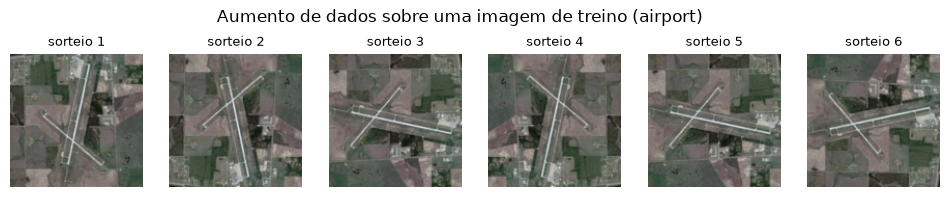

In [7]:
# Exemplo do aumento: a mesma imagem de treino com 5 sorteios diferentes
g = torch.Generator().manual_seed(SEMENTE)
exemplos = aumentar(torch.from_numpy(X_tr[0]).view(1, 3, RESOLUCAO, RESOLUCAO).repeat(6, 1, 1, 1), g).numpy()
fig, eixos = plt.subplots(1, 6, figsize=(12, 2.3))
for ax, img_x, titulo in zip(eixos, exemplos, ["sorteio 1", "sorteio 2", "sorteio 3", "sorteio 4", "sorteio 5", "sorteio 6"]):
    ax.imshow(np.clip(img_x.transpose(1, 2, 0) * desvio + media, 0, 1)); ax.set_title(titulo, fontsize=9); ax.axis("off")
fig.suptitle(f"Aumento de dados sobre uma imagem de treino ({CLASSES[y_tr[0]]})"); plt.show()

### 7.1 MLP-A com aumento de dados

In [26]:
resumo_a_aug, hist_a_aug = treinar(MLPA(), "MLP-A-128_aug", aumento=True)
pd.Series(resumo_a_aug)

[MLP-A-128_aug_preliminar] época   1/200 | treino: perda 1.9986 acc 0.3043 P 0.2703 R 0.3043 F1 0.2611 | val: perda 1.7802 acc 0.4133 P 0.3541 R 0.4133 F1 0.3426 |   2.3s  *checkpoint*
[MLP-A-128_aug_preliminar] época   2/200 | treino: perda 1.7901 acc 0.3935 P 0.3397 R 0.3935 F1 0.3457 | val: perda 1.6609 acc 0.4686 P 0.4363 R 0.4686 F1 0.4127 |   2.3s  *checkpoint*
[MLP-A-128_aug_preliminar] época   3/200 | treino: perda 1.7015 acc 0.4336 P 0.4038 R 0.4335 F1 0.3994 | val: perda 1.5800 acc 0.4981 P 0.4859 R 0.4981 F1 0.4536 |   2.3s  *checkpoint*
[MLP-A-128_aug_preliminar] época   4/200 | treino: perda 1.6243 acc 0.4613 P 0.4343 R 0.4613 F1 0.4344 | val: perda 1.5314 acc 0.5352 P 0.4981 R 0.5352 F1 0.4947 |   2.5s  *checkpoint*
[MLP-A-128_aug_preliminar] época   5/200 | treino: perda 1.5885 acc 0.4754 P 0.4515 R 0.4753 F1 0.4522 | val: perda 1.4681 acc 0.5448 P 0.5278 R 0.5448 F1 0.5198 |   2.6s  *checkpoint*
[MLP-A-128_aug_preliminar] época   6/200 | treino: perda 1.5355 acc 0.4891 

nome_execucao                                   MLP-A-128_aug_preliminar
tipo_execucao                                                 preliminar
parametros                                                      25234570
tamanho_modelo_mb                                                  96.27
epocas_executadas                                                     75
epoca_checkpoint                                                      65
f1_macro_validacao                                                0.6363
acuracia_validacao                                                0.6476
perda_validacao                                                    1.036
tempo_total_s                                                      181.2
tempo_medio_epoca_s                                                 2.42
hardware                                                       Apple MPS
otimizador                                                          adam
taxa_aprendizagem                                  

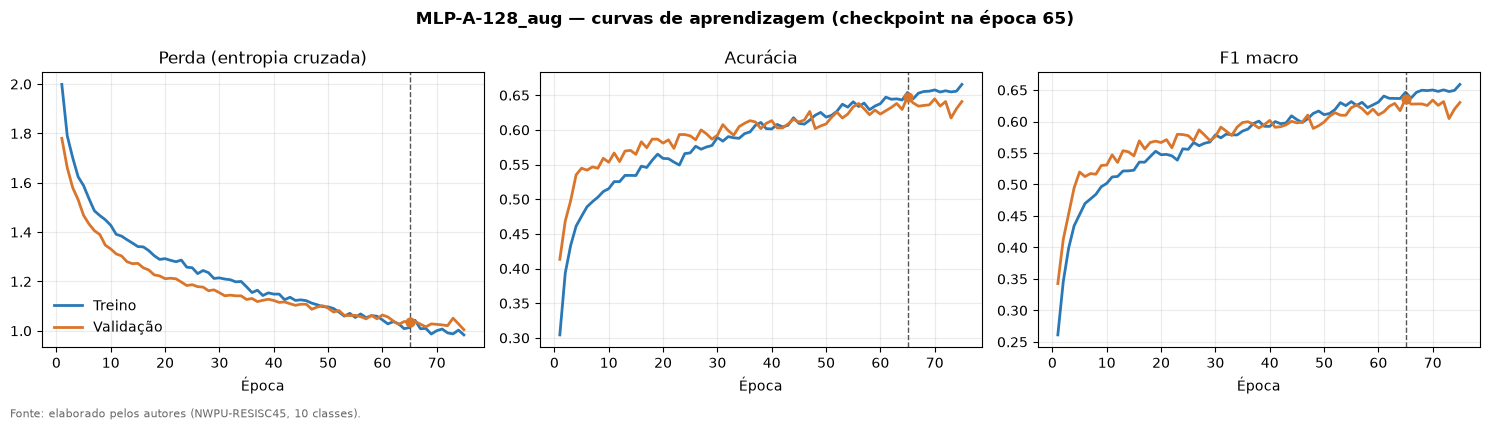

,epoca,perda_treino,acuracia_treino,precisao_macro_treino,recall_macro_treino,f1_macro_treino,perda_validacao,acuracia_validacao,precisao_macro_validacao,recall_macro_validacao,f1_macro_validacao,tempo_epoca_s,checkpoint
0,1,1.9986,0.3043,0.2703,0.3043,0.2611,1.7802,0.4133,0.3541,0.4133,0.3426,2.2890,False
1,2,1.7901,0.3935,0.3397,0.3935,0.3457,1.6609,0.4686,0.4363,0.4686,0.4127,2.3132,False
2,3,1.7015,0.4336,0.4038,0.4335,0.3994,1.5800,0.4981,0.4859,0.4981,0.4536,2.2959,False
3,4,1.6243,0.4613,0.4343,0.4613,0.4344,1.5314,0.5352,0.4981,0.5352,0.4947,2.4642,False
4,5,1.5885,0.4754,0.4515,0.4753,0.4522,1.4681,0.5448,0.5278,0.5448,0.5198,2.5588,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
70,71,1.0071,0.6546,0.6447,0.6546,0.6479,1.0239,0.6343,0.6255,0.6343,0.6257,2.2694,False
71,72,0.9917,0.6565,0.6476,0.6564,0.6503,1.0209,0.6410,0.6308,0.6410,0.6317,2.4320,False
72,73,0.9875,0.6548,0.6447,0.6548,0.6477,1.0511,0.6171,0.6057,0.6171,0.6047,2.4795,False
73,74,1.0028,0.6558,0.6462,0.6558,0.6495,1.0281,0.6305,0.6192,0.6305,0.6196,2.3738,False


In [27]:
plotar_curvas(hist_a_aug, "MLP-A-128_aug")
hist_a_aug.round(4)

### 7.2 MLP-B com aumento de dados

In [28]:
resumo_b_aug, hist_b_aug = treinar(MLPB(), "MLP-B-128_aug", aumento=True)
pd.Series(resumo_b_aug)

[MLP-B-128_aug_preliminar] época   1/200 | treino: perda 2.3526 acc 0.1261 P 0.1345 R 0.1262 F1 0.1149 | val: perda 2.1528 acc 0.2714 P 0.2007 R 0.2714 F1 0.1871 |   2.2s  *checkpoint*
[MLP-B-128_aug_preliminar] época   2/200 | treino: perda 2.2097 acc 0.1913 P 0.1844 R 0.1913 F1 0.1693 | val: perda 2.0611 acc 0.2848 P 0.3062 R 0.2848 F1 0.2016 |   2.5s  *checkpoint*
[MLP-B-128_aug_preliminar] época   3/200 | treino: perda 2.1215 acc 0.2300 P 0.2108 R 0.2300 F1 0.1972 | val: perda 2.0027 acc 0.2914 P 0.3659 R 0.2914 F1 0.2113 |   2.4s  *checkpoint*
[MLP-B-128_aug_preliminar] época   4/200 | treino: perda 2.0535 acc 0.2652 P 0.2456 R 0.2651 F1 0.2325 | val: perda 1.9417 acc 0.3076 P 0.4203 R 0.3076 F1 0.2416 |   2.7s  *checkpoint*
[MLP-B-128_aug_preliminar] época   5/200 | treino: perda 2.0102 acc 0.2874 P 0.2642 R 0.2874 F1 0.2521 | val: perda 1.9022 acc 0.3486 P 0.4321 R 0.3486 F1 0.2987 |   2.2s  *checkpoint*
[MLP-B-128_aug_preliminar] época   6/200 | treino: perda 1.9798 acc 0.2945 

nome_execucao                                   MLP-B-128_aug_preliminar
tipo_execucao                                                 preliminar
parametros                                                      25341386
tamanho_modelo_mb                                                  96.69
epocas_executadas                                                     90
epoca_checkpoint                                                      80
f1_macro_validacao                                                 0.598
acuracia_validacao                                                0.6143
perda_validacao                                                   1.1146
tempo_total_s                                                      224.0
tempo_medio_epoca_s                                                 2.49
hardware                                                       Apple MPS
otimizador                                                          adam
taxa_aprendizagem                                  

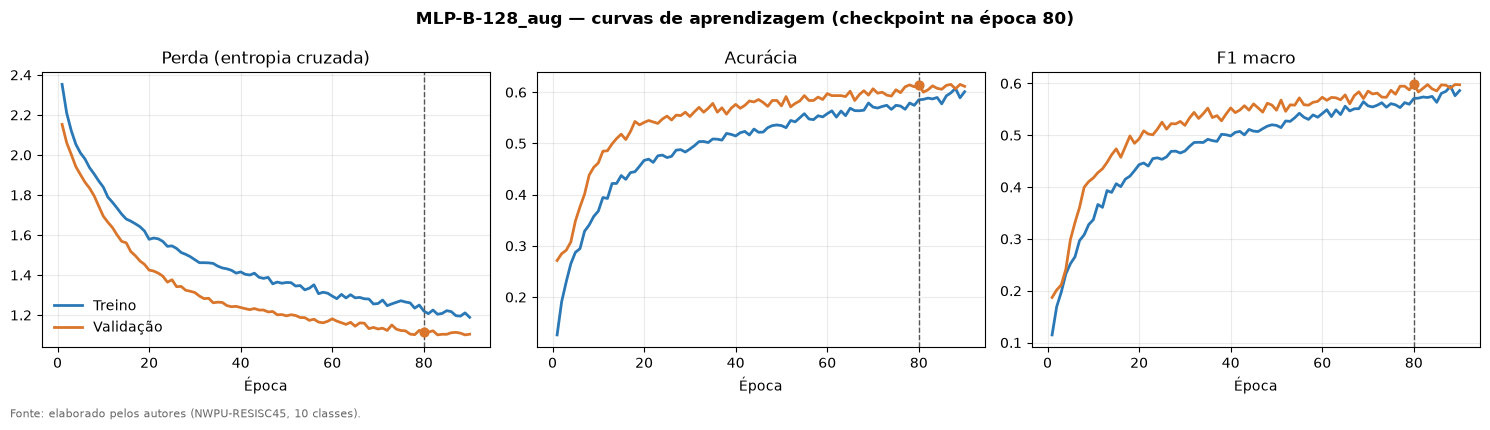

,epoca,perda_treino,acuracia_treino,precisao_macro_treino,recall_macro_treino,f1_macro_treino,perda_validacao,acuracia_validacao,precisao_macro_validacao,recall_macro_validacao,f1_macro_validacao,tempo_epoca_s,checkpoint
0,1,2.3526,0.1261,0.1345,0.1262,0.1149,2.1528,0.2714,0.2007,0.2714,0.1871,2.2369,False
1,2,2.2097,0.1913,0.1844,0.1913,0.1693,2.0611,0.2848,0.3062,0.2848,0.2016,2.5470,False
2,3,2.1215,0.2300,0.2108,0.2300,0.1972,2.0027,0.2914,0.3659,0.2914,0.2113,2.3604,False
3,4,2.0535,0.2652,0.2456,0.2651,0.2325,1.9417,0.3076,0.4203,0.3076,0.2416,2.7392,False
4,5,2.0102,0.2874,0.2642,0.2874,0.2521,1.9022,0.3486,0.4321,0.3486,0.2987,2.2445,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,86,1.2171,0.5928,0.5754,0.5927,0.5807,1.1119,0.6133,0.5965,0.6133,0.5970,2.4361,False
86,87,1.1969,0.5987,0.5797,0.5986,0.5846,1.1136,0.6152,0.5966,0.6152,0.5965,2.4630,False
87,88,1.1948,0.6075,0.5902,0.6074,0.5942,1.1098,0.6067,0.5882,0.6067,0.5910,2.4339,False
88,89,1.2110,0.5891,0.5714,0.5890,0.5762,1.1009,0.6152,0.5988,0.6152,0.5979,2.4663,False


In [29]:
plotar_curvas(hist_b_aug, "MLP-B-128_aug")
hist_b_aug.round(4)

## 8. Terceiro treino: aumento de dados mais forte

Mesmas arquiteturas, mesmos hiperparâmetros, mesmo limite de épocas e mesma paciência. **A única mudança** em relação ao segundo treino é um aumento mais agressivo no conjunto de treino, somado aos espelhamentos e rotações de 90°:

| Transformação | Parâmetros |
|---|---|
| Recorte com zoom | 50 a 100% da área, posição aleatória, reescalado para 128 × 128 (bordas por reflexão) |
| Variação de cor | brilho, contraste e saturação, cada um entre 80% e 120% |
| Apagamento aleatório | com 50% de chance, um retângulo de 10 a 40% do lado vira o valor médio |

Isso deixa o treino mais difícil, e a hipótese é reduzir o sobreajuste. Se o modelo estiver subajustando, o efeito pode ser negativo. Validação e teste **não** recebem aumento. As execuções são `MLP-A-128_aug2_preliminar` e `MLP-B-128_aug2_preliminar`, **separadas** dos treinos anteriores, que não são alterados.

Antes de cada execução deste terceiro treino a semente é fixada de novo (`fixar_semente()`), então o resultado **não depende do que rodou antes** no notebook.

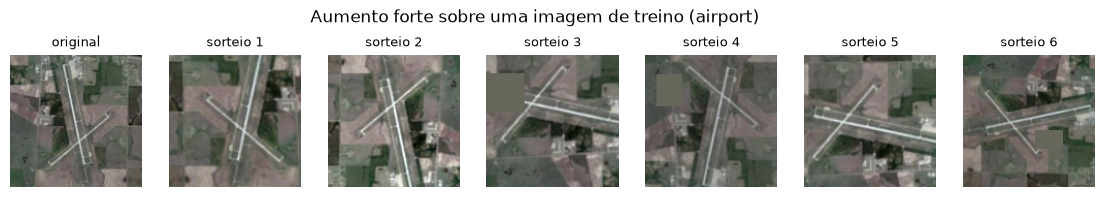

In [8]:
# Exemplo do aumento forte: a mesma imagem de treino com 6 sorteios diferentes
g = torch.Generator().manual_seed(SEMENTE)
base = torch.from_numpy(X_tr[0]).view(1, 3, RESOLUCAO, RESOLUCAO).repeat(6, 1, 1, 1).to(dispositivo)
exemplos = aumentar_forte(aumentar(base, g), g).cpu().numpy()
fig, eixos = plt.subplots(1, 7, figsize=(14, 2.3))
eixos[0].imshow(np.clip(X_tr[0].reshape(3, RESOLUCAO, RESOLUCAO).transpose(1, 2, 0) * desvio + media, 0, 1)); eixos[0].set_title("original", fontsize=9)
for k, (ax, img_x) in enumerate(zip(eixos[1:], exemplos), start=1):
    ax.imshow(np.clip(img_x.transpose(1, 2, 0) * desvio + media, 0, 1)); ax.set_title(f"sorteio {k}", fontsize=9)
for ax in eixos: ax.axis("off")
fig.suptitle(f"Aumento forte sobre uma imagem de treino ({CLASSES[y_tr[0]]})"); plt.show()

### 8.1 MLP-A com aumento forte

In [31]:
fixar_semente()
resumo_a_aug2, hist_a_aug2 = treinar(MLPA(), "MLP-A-128_aug2", aumento="forte")
pd.Series(resumo_a_aug2)

[MLP-A-128_aug2_preliminar] época   1/200 | treino: perda 2.0679 acc 0.2568 P 0.2247 R 0.2567 F1 0.2124 | val: perda 1.8155 acc 0.3686 P 0.3031 R 0.3686 F1 0.2815 |   3.2s  *checkpoint*
[MLP-A-128_aug2_preliminar] época   2/200 | treino: perda 1.8933 acc 0.3374 P 0.3190 R 0.3374 F1 0.2945 | val: perda 1.7083 acc 0.4381 P 0.4111 R 0.4381 F1 0.3701 |   3.9s  *checkpoint*
[MLP-A-128_aug2_preliminar] época   3/200 | treino: perda 1.7777 acc 0.3793 P 0.3541 R 0.3792 F1 0.3450 | val: perda 1.6148 acc 0.4771 P 0.4678 R 0.4771 F1 0.4275 |   3.4s  *checkpoint*
[MLP-A-128_aug2_preliminar] época   4/200 | treino: perda 1.7447 acc 0.3946 P 0.3658 R 0.3945 F1 0.3633 | val: perda 1.5687 acc 0.4867 P 0.4635 R 0.4867 F1 0.4364 |   3.3s  *checkpoint*
[MLP-A-128_aug2_preliminar] época   5/200 | treino: perda 1.6874 acc 0.4215 P 0.3969 R 0.4215 F1 0.3950 | val: perda 1.5066 acc 0.5171 P 0.4973 R 0.5171 F1 0.4864 |   3.4s  *checkpoint*
[MLP-A-128_aug2_preliminar] época   6/200 | treino: perda 1.6491 acc 0

nome_execucao                                  MLP-A-128_aug2_preliminar
tipo_execucao                                                 preliminar
parametros                                                      25234570
tamanho_modelo_mb                                                  96.27
epocas_executadas                                                     34
epoca_checkpoint                                                      24
f1_macro_validacao                                                  0.59
acuracia_validacao                                                0.6048
perda_validacao                                                   1.2472
tempo_total_s                                                      127.7
tempo_medio_epoca_s                                                 3.76
hardware                                                       Apple MPS
otimizador                                                          adam
taxa_aprendizagem                                  

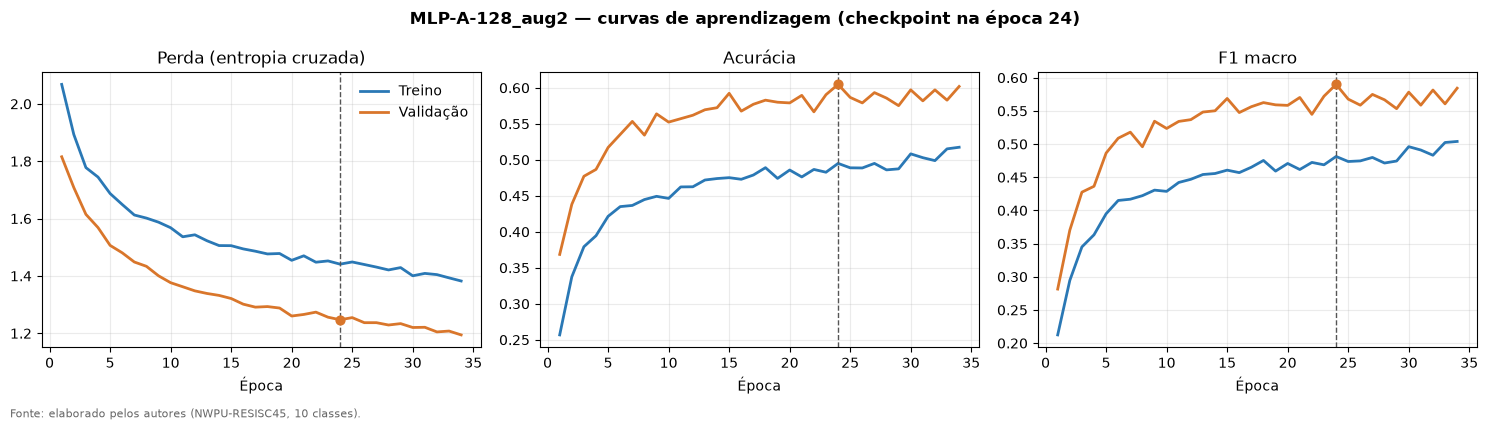

,epoca,perda_treino,acuracia_treino,precisao_macro_treino,recall_macro_treino,f1_macro_treino,perda_validacao,acuracia_validacao,precisao_macro_validacao,recall_macro_validacao,f1_macro_validacao,tempo_epoca_s,checkpoint
0,1,2.0679,0.2568,0.2247,0.2567,0.2124,1.8155,0.3686,0.3031,0.3686,0.2815,3.2234,False
1,2,1.8933,0.3374,0.3190,0.3374,0.2945,1.7083,0.4381,0.4111,0.4381,0.3701,3.9334,False
2,3,1.7777,0.3793,0.3541,0.3792,0.3450,1.6148,0.4771,0.4678,0.4771,0.4275,3.4438,False
3,4,1.7447,0.3946,0.3658,0.3945,0.3633,1.5687,0.4867,0.4635,0.4867,0.4364,3.3431,False
4,5,1.6874,0.4215,0.3969,0.4215,0.3950,1.5066,0.5171,0.4973,0.5171,0.4864,3.3829,False
5,6,1.6491,0.4350,0.4149,0.4349,0.4150,1.4807,0.5352,0.5253,0.5352,0.5088,3.4557,False
6,7,1.6125,0.4366,0.4128,0.4366,0.4169,1.4486,0.5533,0.5265,0.5533,0.5180,3.5610,False
7,8,1.6017,0.4448,0.4193,0.4447,0.4223,1.4336,0.5343,0.5230,0.5343,0.4959,4.0600,False
8,9,1.5875,0.4493,0.4276,0.4492,0.4306,1.4005,0.5638,0.5511,0.5638,0.5344,3.6049,False
9,10,1.5681,0.4464,0.4238,0.4464,0.4287,1.3764,0.5524,0.5288,0.5524,0.5236,4.0536,False


In [32]:
plotar_curvas(hist_a_aug2, "MLP-A-128_aug2")
hist_a_aug2.round(4)

### 8.2 MLP-B com aumento forte

In [33]:
fixar_semente()
resumo_b_aug2, hist_b_aug2 = treinar(MLPB(), "MLP-B-128_aug2", aumento="forte")
pd.Series(resumo_b_aug2)

[MLP-B-128_aug2_preliminar] época   1/200 | treino: perda 2.3226 acc 0.1310 P 0.1380 R 0.1310 F1 0.1271 | val: perda 2.1172 acc 0.3029 P 0.2284 R 0.3029 F1 0.2218 |   4.6s  *checkpoint*
[MLP-B-128_aug2_preliminar] época   2/200 | treino: perda 2.2098 acc 0.1800 P 0.1640 R 0.1800 F1 0.1657 | val: perda 2.0390 acc 0.3371 P 0.3350 R 0.3371 F1 0.2690 |   4.9s  *checkpoint*
[MLP-B-128_aug2_preliminar] época   3/200 | treino: perda 2.1280 acc 0.2274 P 0.1995 R 0.2274 F1 0.2036 | val: perda 1.9577 acc 0.3381 P 0.3440 R 0.3381 F1 0.2799 |   4.8s  *checkpoint*
[MLP-B-128_aug2_preliminar] época   4/200 | treino: perda 2.0672 acc 0.2562 P 0.2268 R 0.2562 F1 0.2282 | val: perda 1.9054 acc 0.3752 P 0.3404 R 0.3752 F1 0.3242 |   4.9s  *checkpoint*
[MLP-B-128_aug2_preliminar] época   5/200 | treino: perda 2.0310 acc 0.2733 P 0.2370 R 0.2733 F1 0.2414 | val: perda 1.8731 acc 0.3762 P 0.3344 R 0.3762 F1 0.3260 |   4.8s  *checkpoint*
[MLP-B-128_aug2_preliminar] época   6/200 | treino: perda 1.9967 acc 0

nome_execucao                                  MLP-B-128_aug2_preliminar
tipo_execucao                                                 preliminar
parametros                                                      25341386
tamanho_modelo_mb                                                  96.69
epocas_executadas                                                     78
epoca_checkpoint                                                      68
f1_macro_validacao                                                0.5726
acuracia_validacao                                                 0.599
perda_validacao                                                    1.213
tempo_total_s                                                      348.5
tempo_medio_epoca_s                                                 4.47
hardware                                                       Apple MPS
otimizador                                                          adam
taxa_aprendizagem                                  

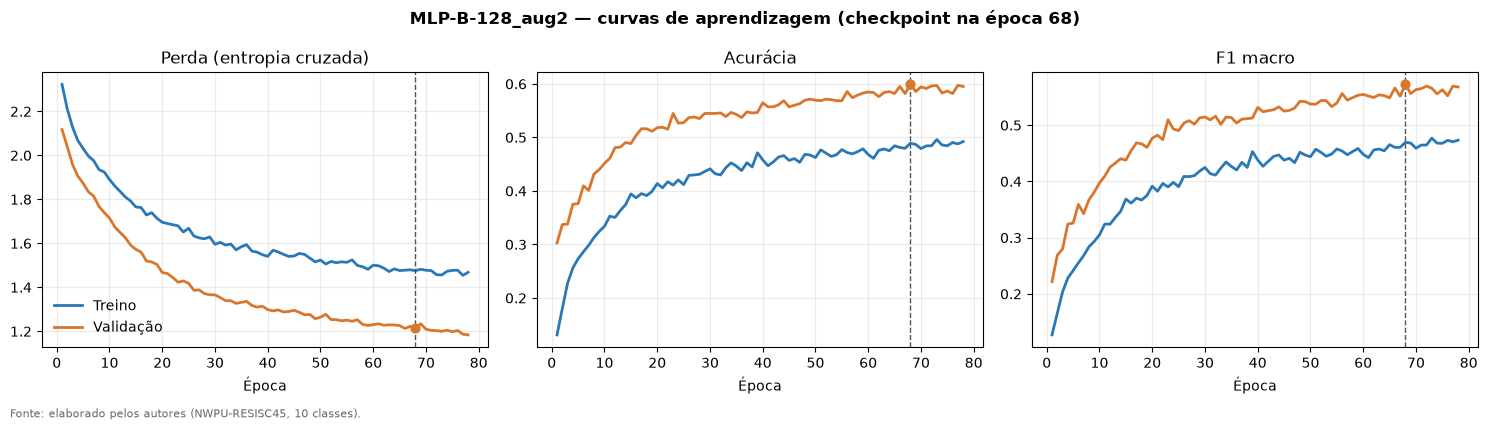

,epoca,perda_treino,acuracia_treino,precisao_macro_treino,recall_macro_treino,f1_macro_treino,perda_validacao,acuracia_validacao,precisao_macro_validacao,recall_macro_validacao,f1_macro_validacao,tempo_epoca_s,checkpoint
0,1,2.3226,0.1310,0.1380,0.1310,0.1271,2.1172,0.3029,0.2284,0.3029,0.2218,4.5823,False
1,2,2.2098,0.1800,0.1640,0.1800,0.1657,2.0390,0.3371,0.3350,0.3371,0.2690,4.8543,False
2,3,2.1280,0.2274,0.1995,0.2274,0.2036,1.9577,0.3381,0.3440,0.3381,0.2799,4.7785,False
3,4,2.0672,0.2562,0.2268,0.2562,0.2282,1.9054,0.3752,0.3404,0.3752,0.3242,4.8662,False
4,5,2.0310,0.2733,0.2370,0.2733,0.2414,1.8731,0.3762,0.3344,0.3762,0.3260,4.7816,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
73,74,1.4727,0.4858,0.4625,0.4858,0.4681,1.2048,0.5829,0.5536,0.5829,0.5556,3.8744,False
74,75,1.4770,0.4844,0.4631,0.4843,0.4678,1.1980,0.5867,0.5627,0.5867,0.5631,4.1028,False
75,76,1.4777,0.4905,0.4680,0.4904,0.4731,1.2036,0.5819,0.5500,0.5819,0.5524,3.7538,False
76,77,1.4544,0.4879,0.4640,0.4878,0.4706,1.1868,0.5971,0.5695,0.5971,0.5696,3.6337,False


In [34]:
plotar_curvas(hist_b_aug2, "MLP-B-128_aug2")
hist_b_aug2.round(4)

## 9. Comparação: sem aumento × aumento leve × aumento forte

A coluna `dif_f1_treino_val` é o F1 macro de treino menos o de validação no checkpoint. Quanto menor, menos sobreajuste.

In [35]:
linhas = []
for rotulo, resumo, hist in [("MLP-A-128", resumo_a, hist_a), ("MLP-A-128 + aumento", resumo_a_aug, hist_a_aug),
                             ("MLP-A-128 + aumento forte", resumo_a_aug2, hist_a_aug2),
                             ("MLP-B-128", resumo_b, hist_b), ("MLP-B-128 + aumento", resumo_b_aug, hist_b_aug),
                             ("MLP-B-128 + aumento forte", resumo_b_aug2, hist_b_aug2)]:
    ck = hist[hist["checkpoint"]].iloc[0]
    linhas.append({"modelo": rotulo, "f1_macro_val": resumo["f1_macro_validacao"], "acuracia_val": resumo["acuracia_validacao"],
                   "dif_f1_treino_val": round(ck["f1_macro_treino"] - ck["f1_macro_validacao"], 4),
                   "epoca_checkpoint": resumo["epoca_checkpoint"], "epocas": resumo["epocas_executadas"],
                   "tempo_total_s": resumo["tempo_total_s"]})
comparacao = pd.DataFrame(linhas).set_index("modelo")
print(comparacao.to_string())
comparacao

                           f1_macro_val  acuracia_val  dif_f1_treino_val  epoca_checkpoint  epocas  tempo_total_s
modelo                                                                                                           
MLP-A-128                        0.5359        0.5448             0.2170                19      29           53.6
MLP-A-128 + aumento              0.6363        0.6476             0.0101                65      75          181.2
MLP-A-128 + aumento forte        0.5900        0.6048            -0.1086                24      34          127.7
MLP-B-128                        0.5353        0.5419             0.1239                41      51           99.5
MLP-B-128 + aumento              0.5980        0.6143            -0.0272                80      90          224.0
MLP-B-128 + aumento forte        0.5726        0.5990            -0.1031                68      78          348.5


,f1_macro_val,acuracia_val,dif_f1_treino_val,epoca_checkpoint,epocas,tempo_total_s
modelo,,,,,,
MLP-A-128,0.5359,0.5448,0.2170,19,29,53.6
MLP-A-128 + aumento,0.6363,0.6476,0.0101,65,75,181.2
MLP-A-128 + aumento forte,0.5900,0.6048,-0.1086,24,34,127.7
MLP-B-128,0.5353,0.5419,0.1239,41,51,99.5
MLP-B-128 + aumento,0.5980,0.6143,-0.0272,80,90,224.0
MLP-B-128 + aumento forte,0.5726,0.5990,-0.1031,68,78,348.5


## 10. Gráficos comparativos dos seis treinos

Cinco gráficos que resumem a diferença entre as MLPs. Eles leem `resultados/experimentos.csv` e `resultados/historicos/` e salvam os arquivos `comparacao_*.png` em `resultados/figuras/mlp/`. Rode depois dos seis treinos.

1. **F1 macro na validação:** barras das seis execuções, para comparar as receitas lado a lado.
2. **Curvas da validação por época:** mostram por quanto tempo cada receita continua melhorando.
3. **Treino × validação por época:** uma janela por execução, para ver o sobreajuste.
4. **Diferença entre treino e validação:** no melhor ponto de cada treino, que é o modelo guardado.
5. **Custo × desempenho:** tempo de treino contra F1 macro.

Cores: azul é sem aumento, laranja é aumento leve e verde é aumento forte.

In [ ]:
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, MultipleLocator


def graficos_comparativos(raiz, saida):
    saida.mkdir(parents=True, exist_ok=True)

    # --- cores e estilo (paleta validada: blue / orange / aqua; texto sempre em tinta, nunca na cor da série) ---
    SUPERFICIE, TINTA, TINTA_2, TINTA_3, GRADE = "#fcfcfb", "#0b0b0b", "#52514e", "#8a8984", "#e6e5e1"
    RECEITAS = {  # chave: (sufixo do nome, rótulo, cor)
        "sem": ("", "Sem aumento", "#2a78d6"),
        "leve": ("_aug", "Aumento leve", "#eb6834"),
        "forte": ("_aug2", "Aumento forte", "#1baf7a"),
    }
    ARQS = {"A": "MLP-A (512 → 128)", "B": "MLP-B (512 → 256 → 128 → 64)"}
    FONTE = "Fonte: elaborado pelos autores (NWPU-RESISC45, 10 classes). Dados de validação; o teste não foi usado."

    plt.rcParams.update({
        "font.family": "DejaVu Sans", "font.size": 10, "text.color": TINTA, "axes.labelcolor": TINTA_2,
        "xtick.color": TINTA_2, "ytick.color": TINTA_2, "axes.edgecolor": GRADE, "axes.facecolor": SUPERFICIE,
        "figure.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE, "axes.spines.top": False,
        "axes.spines.right": False, "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.8,
        "axes.axisbelow": True, "legend.frameon": False,
    })

    # --- dados ---
    exp = pd.read_csv(raiz / "resultados" / "experimentos.csv").set_index("nome_execucao")
    R = {}
    for a in ARQS:
        for k, (suf, rot, cor) in RECEITAS.items():
            nome = f"MLP-{a}-128{suf}_preliminar"
            h = pd.read_csv(raiz / "resultados" / "historicos" / f"{nome}_historico.csv")
            ck = h[h["checkpoint"]].iloc[0]
            R[(a, k)] = dict(nome=nome, h=h, ck=ck, f1=exp.loc[nome, "f1_macro_validacao"], acc=exp.loc[nome, "acuracia_validacao"],
                             tempo=exp.loc[nome, "tempo_total_s"], epocas=int(exp.loc[nome, "epocas_executadas"]),
                             f1_tr=ck["f1_macro_treino"], dif=ck["f1_macro_treino"] - ck["f1_macro_validacao"])
    pt = lambda x, d=3: f"{x:.{d}f}".replace(".", ",")
    virgula = FuncFormatter(lambda v, _: f"{v:.1f}".replace(".", ","))


    def titulo(fig, texto, sub):
        fig.text(0.055, 0.965, texto, fontsize=14, fontweight="bold", ha="left", va="top")
        fig.text(0.055, 0.915, sub, fontsize=10, color=TINTA_2, ha="left", va="top")


    def rodape(fig):
        fig.text(0.055, 0.015, FONTE, fontsize=8, color=TINTA_3, ha="left", va="bottom")


    def legenda_receitas(fig, x=0.055, y=0.865):
        hs = [Line2D([0], [0], marker="s", color="none", markerfacecolor=c, markeredgecolor="none", markersize=10, label=r) for _, r, c in RECEITAS.values()]
        fig.legend(handles=hs, loc="upper left", bbox_to_anchor=(x, y), ncol=3, fontsize=10, labelcolor=TINTA_2, handletextpad=0.3, columnspacing=1.6)


    # ---------- 1) barras: F1 macro de validação ----------
    fig, ax = plt.subplots(figsize=(10, 5.8))
    fig.subplots_adjust(left=0.08, right=0.97, top=0.78, bottom=0.12)
    larg = 0.26
    for i, a in enumerate(ARQS):
        for j, (k, (_, rot, cor)) in enumerate(RECEITAS.items()):
            x = i + (j - 1) * (larg + 0.02)
            v = R[(a, k)]["f1"]
            ax.bar(x, v, width=larg, color=cor, edgecolor=SUPERFICIE, linewidth=2, zorder=3)
            ax.text(x, v + 0.012, pt(v), ha="center", va="bottom", fontsize=10.5, fontweight="bold", color=TINTA)
    ax.set_xticks(range(len(ARQS))); ax.set_xticklabels(list(ARQS.values()), fontsize=11, color=TINTA)
    ax.set_ylim(0, 0.75); ax.set_ylabel("F1 macro na validação"); ax.yaxis.set_major_formatter(virgula)
    ax.grid(axis="x", visible=False); ax.tick_params(axis="x", length=0)
    titulo(fig, "O aumento de dados leve foi o que mais ajudou as MLPs", "F1 macro na validação, no melhor ponto de cada treino (maior é melhor)")
    legenda_receitas(fig); rodape(fig)
    fig.savefig(saida / "comparacao_1_f1_validacao.png", dpi=200); plt.show()

    # ---------- 2) curvas do F1 de validação por época ----------
    fig, eixos = plt.subplots(1, 2, figsize=(12, 5.4), sharey=True)
    fig.subplots_adjust(left=0.07, right=0.97, top=0.76, bottom=0.14, wspace=0.08)
    for ax, a in zip(eixos, ARQS):
        for k, (_, rot, cor) in RECEITAS.items():
            d = R[(a, k)]; h = d["h"]
            ax.plot(h["epoca"], h["f1_macro_validacao"], color=cor, lw=2, zorder=3)
            ep = int(d["ck"]["epoca"])
            ax.plot([ep], [d["f1"]], marker="o", markersize=9, color=cor, markeredgecolor=SUPERFICIE, markeredgewidth=2, zorder=4)
            dy = -0.03 if (a, k) == ("A", "forte") else 0
            ax.text(h["epoca"].iloc[-1] + 1.2, h["f1_macro_validacao"].iloc[-1] + dy, rot, color=TINTA_2, fontsize=9, va="center")
        ax.set_title(ARQS[a], fontsize=11, loc="left", color=TINTA, pad=8)
        ax.set_xlabel("Época"); ax.set_xlim(0, 112); ax.set_ylim(0.2, 0.7)
        ax.grid(axis="x", visible=False); ax.yaxis.set_major_formatter(virgula)
    eixos[0].set_ylabel("F1 macro na validação")
    titulo(fig, "Com o aumento leve a validação continua melhorando por muito mais tempo",
           "F1 macro na validação por época. O ponto marca a melhor época, que é o modelo guardado.")
    legenda_receitas(fig); rodape(fig)
    fig.savefig(saida / "comparacao_2_curvas_validacao.png", dpi=200); plt.show()

    # ---------- 3) treino × validação por época (2 x 3) ----------
    fig, eixos = plt.subplots(2, 3, figsize=(13, 7), sharey=True)
    fig.subplots_adjust(left=0.065, right=0.98, top=0.77, bottom=0.13, wspace=0.07, hspace=0.32)
    for r, a in enumerate(ARQS):
        for c, (k, (_, rot, cor)) in enumerate(RECEITAS.items()):
            ax = eixos[r, c]; d = R[(a, k)]; h = d["h"]; ep = int(d["ck"]["epoca"])
            ax.plot(h["epoca"], h["f1_macro_treino"], color=TINTA_2, lw=1.6, ls=(0, (4, 2)), zorder=2)
            ax.plot(h["epoca"], h["f1_macro_validacao"], color=cor, lw=2.2, zorder=3)
            ax.plot([ep], [d["f1"]], marker="o", markersize=9, color=cor, markeredgecolor=SUPERFICIE, markeredgewidth=2, zorder=4)
            ax.set_title(f"{rot}", fontsize=10.5, loc="left", color=TINTA, pad=6)
            ax.text(0.97, 0.06, f"diferença no melhor ponto: {'+' if d['dif'] >= 0 else '−'}{pt(abs(d['dif']), 2)}",
                    transform=ax.transAxes, ha="right", fontsize=9, color=TINTA_2)
            ax.set_ylim(0, 0.95); ax.set_xlim(0, max(h["epoca"]) + 2)
            ax.grid(axis="x", visible=False); ax.yaxis.set_major_formatter(virgula)
            if c == 0: ax.set_ylabel(f"{ARQS[a].split(' ')[0]}\nF1 macro", fontsize=10, color=TINTA)
            if r == 1: ax.set_xlabel("Época")
    hs = [Line2D([0], [0], color=TINTA_2, lw=1.6, ls=(0, (4, 2)), label="Treino"),
          Line2D([0], [0], color=TINTA_2, lw=2.2, label="Validação (a cor muda com a receita)"),
          Line2D([0], [0], marker="o", color="none", markerfacecolor=TINTA_2, markersize=8, label="Melhor época (modelo guardado)")]
    fig.legend(handles=hs, loc="upper left", bbox_to_anchor=(0.055, 0.865), ncol=3, fontsize=10, labelcolor=TINTA_2)
    titulo(fig, "Sem aumento a rede vai bem no treino e mal na validação; com aumento as curvas se aproximam",
           "F1 macro por época. O aumento forte deixa o treino tão difícil que o treino fica abaixo da validação.")
    rodape(fig)
    fig.savefig(saida / "comparacao_3_treino_vs_validacao.png", dpi=200); plt.show()

    # ---------- 4) halteres: F1 de treino × validação no melhor ponto ----------
    fig, ax = plt.subplots(figsize=(10, 5.8))
    fig.subplots_adjust(left=0.27, right=0.85, top=0.78, bottom=0.12)
    linhas = [(a, k) for a in ARQS for k in RECEITAS]
    for y, (a, k) in enumerate(reversed(linhas)):
        d = R[(a, k)]; cor = RECEITAS[k][2]
        ax.plot([d["f1"], d["f1_tr"]], [y, y], color=GRADE, lw=4, solid_capstyle="round", zorder=2)
        ax.plot([d["f1_tr"]], [y], marker="o", markersize=10, markerfacecolor=SUPERFICIE, markeredgecolor=TINTA_2, markeredgewidth=2, zorder=4)
        ax.plot([d["f1"]], [y], marker="o", markersize=11, color=cor, markeredgecolor=SUPERFICIE, markeredgewidth=2, zorder=5)
        ax.text(1.03, y, f"{'+' if d['dif'] >= 0 else '−'}{pt(abs(d['dif']), 2)}", transform=ax.get_yaxis_transform(), ha="left", va="center", fontsize=10.5, fontweight="bold", color=TINTA)
    ax.set_yticks(range(len(linhas)))
    ax.set_yticklabels([f"{ARQS[a].split(' ')[0]} · {RECEITAS[k][1].lower()}" for a, k in reversed(linhas)], fontsize=10.5, color=TINTA)
    ax.set_xlim(0.4, 0.8); ax.set_ylim(-0.6, len(linhas) - 0.4); ax.set_xlabel("F1 macro"); ax.xaxis.set_major_locator(MultipleLocator(0.1)); ax.xaxis.set_major_formatter(virgula)
    ax.grid(axis="y", visible=False); ax.tick_params(axis="y", length=0)
    ax.text(1.03, len(linhas) - 0.45, "diferença\n(treino − val.)", transform=ax.get_yaxis_transform(), ha="left", va="bottom", fontsize=9, color=TINTA_2)
    hs = [Line2D([0], [0], marker="o", color="none", markerfacecolor=SUPERFICIE, markeredgecolor=TINTA_2, markeredgewidth=2, markersize=9, label="F1 no treino"),
          Line2D([0], [0], marker="o", color="none", markerfacecolor=TINTA_2, markersize=9, label="F1 na validação (cor da receita)")]
    fig.legend(handles=hs, loc="upper left", bbox_to_anchor=(0.055, 0.865), ncol=2, fontsize=10, labelcolor=TINTA_2)
    titulo(fig, "O aumento leve zera a distância entre treino e validação; o forte a inverte", "F1 macro no melhor ponto de cada treino (o modelo guardado)")
    rodape(fig)
    fig.savefig(saida / "comparacao_4_diferenca_treino_validacao.png", dpi=200); plt.show()

    # ---------- 5) custo × desempenho ----------
    fig, ax = plt.subplots(figsize=(10, 5.8))
    fig.subplots_adjust(left=0.09, right=0.96, top=0.76, bottom=0.12)
    marcas = {"A": "o", "B": "s"}
    for (a, k), d in R.items():
        cor = RECEITAS[k][2]
        ax.plot([d["tempo"]], [d["f1"]], marker=marcas[a], markersize=13, color=cor, markeredgecolor=SUPERFICIE, markeredgewidth=2, linestyle="none", zorder=4)
        deslocamento, va = ((12, -8), "top") if (a, k) == ("B", "sem") else ((11, 9), "baseline")
        ax.annotate(f"{a} · {RECEITAS[k][1].lower()}", (d["tempo"], d["f1"]), xytext=deslocamento, va=va, textcoords="offset points", fontsize=9.5, color=TINTA_2)
    ax.set_xlabel("Tempo total de treino (segundos)"); ax.set_ylabel("F1 macro na validação")
    ax.set_xlim(0, 410); ax.set_ylim(0.5, 0.67); ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.2f}".replace(".", ",")))
    ax.grid(axis="x", visible=False)
    hs = [Line2D([0], [0], marker="s", color="none", markerfacecolor=c, markeredgecolor="none", markersize=10, label=r) for _, r, c in RECEITAS.values()]
    hs += [Line2D([0], [0], marker="o", color="none", markerfacecolor=TINTA_3, markeredgecolor="none", markersize=10, label="MLP-A"),
           Line2D([0], [0], marker="s", color="none", markerfacecolor=TINTA_3, markeredgecolor="none", markersize=10, label="MLP-B")]
    fig.legend(handles=hs, loc="upper left", bbox_to_anchor=(0.055, 0.865), ncol=5, fontsize=10, labelcolor=TINTA_2, handletextpad=0.3, columnspacing=1.2)
    titulo(fig, "Treinar por mais tempo não rendeu um modelo melhor", "Tempo de treino × F1 macro na validação (tempo medido no Mac, com o chip Apple MPS)")
    rodape(fig)
    fig.savefig(saida / "comparacao_5_custo_desempenho.png", dpi=200); plt.show()


graficos_comparativos(RAIZ, RAIZ / "resultados" / "figuras" / "mlp")

## 11. Leitura dos resultados (preencher após rodar)

- F1 macro e acurácia de validação no checkpoint de cada MLP, sem aumento, com aumento leve e com aumento forte: …
- O aumento de dados reduziu a distância entre treino e validação? Mudou a época do checkpoint? O forte ajudou ou atrapalhou? …
- Custo: parâmetros, tamanho do `.pt`, tempo médio por época: …
- Próximos passos: ajuste de lr e dropout (buscas identificadas como preliminares) e treino final no Colab.

---

# Parte 2: hiperparâmetros com Optuna e retreino das MLPs

As seções 1 a 11 acima **não foram alteradas**. Daqui em diante o notebook busca hiperparâmetros melhores com o [Optuna](https://optuna.org) e retreina as seis MLPs com eles, **sem sobrescrever** nenhum arquivo dos treinos anteriores: todos os arquivos novos levam `_opt` no nome.

## 12. Busca de hiperparâmetros com Optuna

O Optuna testa combinações de hiperparâmetros e usa o resultado de cada tentativa para escolher a próxima (algoritmo TPE). Tentativas que vão mal cedo são interrompidas (poda), o que economiza tempo.

**Regras que seguimos (enunciado do projeto)**

- A busca é uma **busca adicional**, identificada à parte das execuções finais.
- Quem decide é o **F1 macro na validação**. O **teste não é usado**.
- A semente é a mesma (42) em todas as tentativas.

**Como a busca foi montada**

| Item | Valor |
|---|---|
| Uma busca por MLP | MLP-A e MLP-B, cada uma com o seu estudo |
| Aumento de dados nas tentativas | leve (espelhamentos e rotações de 90°), a receita que foi melhor até aqui |
| O que se maximiza | o melhor F1 macro de validação da tentativa |
| Tentativas por MLP | `N_TRIALS` (padrão 20) |
| Limite de épocas por tentativa | `EPOCAS_TRIAL` (padrão 60), com a mesma parada antecipada (paciência 10) |
| Poda | `MedianPruner`: corta a tentativa que fica abaixo da mediana das anteriores |

**Hiperparâmetros buscados**

| Hiperparâmetro | Faixa | O que é |
|---|---|---|
| `lr` | 1e-5 a 3e-3 (escala log) | velocidade de aprendizado |
| `weight_decay` | 1e-6 a 1e-2 (escala log) | multa para pesos grandes |
| `dropout` | 0,2 a 0,7, de 0,1 em 0,1 | fração de neurônios desligados no treino |
| `lote` | 32, 64 ou 128 | imagens por lote |

As arquiteturas (camadas) **não mudam**. O que muda é o treino e o dropout.

O estudo fica salvo em `resultados/optuna/mlp.db`, então se o notebook for interrompido basta rodar a célula de novo: ela continua de onde parou. Para recomeçar do zero, apague esse arquivo.

In [13]:
import optuna
from optuna.pruners import MedianPruner
from optuna.samplers import TPESampler

optuna.logging.set_verbosity(optuna.logging.WARNING)

N_TRIALS = 20        # tentativas por MLP
EPOCAS_TRIAL = 60    # limite de épocas em cada tentativa (a parada antecipada continua valendo)
DIR_OPTUNA = RAIZ / "resultados" / "optuna"
DIR_OPTUNA.mkdir(parents=True, exist_ok=True)
print("optuna", optuna.__version__, "| tentativas por MLP:", N_TRIALS, "| épocas por tentativa:", EPOCAS_TRIAL)

optuna 5.1.0 | tentativas por MLP: 20 | épocas por tentativa: 60


### 12.1 MLPs com dropout ajustável

São as mesmas camadas da `MLPA` e da `MLPB`. A única diferença é que o dropout vira um parâmetro, para o Optuna poder testar valores diferentes de 0,5. As classes originais continuam como estavam.

In [14]:
class MLPA_HP(nn.Module):
    def __init__(self, dropout, n_classes=10):
        super().__init__()
        self.rede = nn.Sequential(
            nn.Linear(3 * RESOLUCAO * RESOLUCAO, 512), nn.BatchNorm1d(512), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(512, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(128, n_classes))

    def forward(self, x):
        return self.rede(x.flatten(1))


class MLPB_HP(nn.Module):
    def __init__(self, dropout, n_classes=10):
        super().__init__()
        self.rede = nn.Sequential(
            nn.Linear(3 * RESOLUCAO * RESOLUCAO, 512), nn.BatchNorm1d(512), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(512, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(256, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(128, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(64, n_classes))

    def forward(self, x):
        return self.rede(x.flatten(1))


# confere que as camadas são as mesmas das MLPs originais (com dropout 0,5 os parâmetros são idênticos)
for Original, Nova in ((MLPA, MLPA_HP), (MLPB, MLPB_HP)):
    assert sum(p.numel() for p in Original().parameters()) == sum(p.numel() for p in Nova(0.5).parameters())
    print(Nova.__name__, f"{sum(p.numel() for p in Nova(0.5).parameters()):,} parâmetros (igual à {Original.__name__})")

MLPA_HP 25,234,570 parâmetros (igual à MLPA)
MLPB_HP 25,341,386 parâmetros (igual à MLPB)


### 12.2 Função de treino com hiperparâmetros

É o mesmo laço de treino da seção 4, só que recebe `lr`, `weight_decay`, `lote` e `max_epocas` como argumentos. Ela serve para as duas coisas:

- **dentro do Optuna** (`trial` informado, `salvar=False`): treina em silêncio, reporta o F1 de validação a cada época e pode ser podada;
- **nos retreinos finais** (`salvar=True`): grava checkpoint, histórico, configuração e a linha em `experimentos.csv`, sempre com nome novo (`_opt`).

A função `treinar` original **não é usada nem alterada** aqui.

In [15]:
DESCRICOES_AUMENTO = {
    False: "nenhum",
    True: "espelhamentos e rotações de 90° (só no treino)",
    "forte": "espelhamentos e rotações de 90°, recorte com zoom (50-100% da área), variação de cor (brilho, contraste e saturação ±20%) "
             "e apagamento aleatório (p = 0,5; 10-40% do lado), só no treino",
}
NOMES_ANTIGOS = {f"MLP-{a}-128{s}_preliminar" for a in "AB" for s in ("", "_aug", "_aug2")}  # treinos que NÃO podem ser sobrescritos


def treinar_hp(modelo, nome, aumento, lr, weight_decay, lote, max_epocas, trial=None, salvar=True, extras=None):
    descricao_aumento = DESCRICOES_AUMENTO[aumento]
    nome_execucao = nome + "_preliminar"
    if salvar:
        assert nome_execucao not in NOMES_ANTIGOS, "este nome é de um treino anterior e não pode ser sobrescrito"
    extras = {"arquitetura": nome, "classe": type(modelo).__name__, "aumento_de_dados": descricao_aumento, **(extras or {})}
    gerador_aug = torch.Generator().manual_seed(SEMENTE)
    modelo = modelo.to(dispositivo)
    perda_fn = nn.CrossEntropyLoss()
    otimizador = torch.optim.Adam(modelo.parameters(), lr=lr, weight_decay=weight_decay)
    loader_tr = DataLoader(TensorDataset(torch.from_numpy(X_tr), torch.from_numpy(y_tr)), batch_size=lote,
                           shuffle=True, generator=torch.Generator().manual_seed(SEMENTE))
    loader_va = DataLoader(TensorDataset(torch.from_numpy(X_va), torch.from_numpy(y_va)), batch_size=lote)

    def epoca(loader, treino):
        modelo.train(treino)
        soma, previstas, reais = 0.0, [], []
        with torch.set_grad_enabled(treino):
            for xb, yb in loader:
                xb, yb = xb.to(dispositivo), yb.to(dispositivo)
                if treino and aumento:
                    xb = aumentar(xb.view(-1, 3, RESOLUCAO, RESOLUCAO), gerador_aug)
                    if aumento == "forte":
                        xb = aumentar_forte(xb, gerador_aug)
                logits = modelo(xb)
                perda = perda_fn(logits, yb)
                if treino:
                    otimizador.zero_grad(set_to_none=True)
                    perda.backward()
                    otimizador.step()
                soma += perda.item() * len(yb)
                previstas.append(logits.argmax(1).cpu())
                reais.append(yb.cpu())
        p, r = torch.cat(previstas).numpy(), torch.cat(reais).numpy()
        macro = dict(average="macro", zero_division=0)
        return (soma / len(r), accuracy_score(r, p), precision_score(r, p, **macro),
                recall_score(r, p, **macro), f1_score(r, p, **macro))

    caminho_ckpt = RAIZ / "modelos" / f"{nome_execucao}.pt"
    if salvar:
        (RAIZ / "modelos").mkdir(exist_ok=True)
    historico, melhor_f1, melhor_epoca, sem_melhora, tempo_total = [], -1.0, 0, 0, 0.0

    for n in range(1, max_epocas + 1):
        if dispositivo.type == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter()
        tr = epoca(loader_tr, True)
        va = epoca(loader_va, False)
        if dispositivo.type == "cuda": torch.cuda.synchronize()
        dt = time.perf_counter() - t0
        tempo_total += dt
        historico.append({"epoca": n,
                          "perda_treino": tr[0], "acuracia_treino": tr[1], "precisao_macro_treino": tr[2],
                          "recall_macro_treino": tr[3], "f1_macro_treino": tr[4],
                          "perda_validacao": va[0], "acuracia_validacao": va[1], "precisao_macro_validacao": va[2],
                          "recall_macro_validacao": va[3], "f1_macro_validacao": va[4], "tempo_epoca_s": dt})
        melhorou = va[4] > melhor_f1
        if melhorou:
            melhor_f1, melhor_epoca, sem_melhora = va[4], n, 0
            if salvar:
                torch.save({"state_dict": modelo.state_dict(), "epoca": n, "f1_macro_validacao": va[4]}, caminho_ckpt)
        else:
            sem_melhora += 1
        if salvar:
            print(f"[{nome_execucao}] época {n:3d}/{max_epocas} | "
                  f"treino: perda {tr[0]:.4f} acc {tr[1]:.4f} P {tr[2]:.4f} R {tr[3]:.4f} F1 {tr[4]:.4f} | "
                  f"val: perda {va[0]:.4f} acc {va[1]:.4f} P {va[2]:.4f} R {va[3]:.4f} F1 {va[4]:.4f} | {dt:5.1f}s"
                  + ("  *checkpoint*" if melhorou else ""))
        if trial is not None:                      # Optuna: reporta e deixa o Optuna podar a tentativa
            trial.report(va[4], n)
            if trial.should_prune():
                raise optuna.TrialPruned()
        if sem_melhora >= PACIENCIA:
            if salvar:
                print(f"Parada antecipada: {PACIENCIA} épocas sem melhora no F1 macro de validação.")
            break

    hist = pd.DataFrame(historico)
    hist["checkpoint"] = hist["epoca"] == melhor_epoca
    if not salvar:
        return None, hist

    (RAIZ / "resultados" / "historicos").mkdir(parents=True, exist_ok=True)
    hist.to_csv(RAIZ / "resultados" / "historicos" / f"{nome_execucao}_historico.csv", index=False)
    ck = hist[hist["checkpoint"]].iloc[0]
    resumo = {
        "nome_execucao": nome_execucao, "tipo_execucao": "preliminar_optuna",
        "parametros": sum(p.numel() for p in modelo.parameters()),
        "tamanho_modelo_mb": round(caminho_ckpt.stat().st_size / 1024**2, 2),
        "epocas_executadas": len(hist), "epoca_checkpoint": melhor_epoca,
        "f1_macro_validacao": round(float(ck["f1_macro_validacao"]), 4),
        "acuracia_validacao": round(float(ck["acuracia_validacao"]), 4),
        "perda_validacao": round(float(ck["perda_validacao"]), 4),
        "tempo_total_s": round(tempo_total, 1), "tempo_medio_epoca_s": round(tempo_total / len(hist), 2),
        "hardware": hardware, "otimizador": "adam", "taxa_aprendizagem": lr, "weight_decay": weight_decay,
        "tamanho_lote": lote, "max_epocas": max_epocas, "paciencia": PACIENCIA,
        "criterio_parada": "F1 macro de validação", "semente": SEMENTE, "torch": torch.__version__,
        "extras": json.dumps(extras, ensure_ascii=False),
    }
    print()
    print(f"Resumo {nome_execucao}: checkpoint na época {melhor_epoca} de {len(hist)} | {resumo['parametros']:,} parâmetros | "
          f"{tempo_total:.1f}s no total ({tempo_total / len(hist):.2f}s/época)")
    for rotulo, sufixo in (("treino   ", "treino"), ("validação", "validacao")):
        print(f"  {rotulo} : perda {ck['perda_' + sufixo]:.4f} | acurácia {ck['acuracia_' + sufixo]:.4f} | "
              f"precisão macro {ck['precisao_macro_' + sufixo]:.4f} | recall macro {ck['recall_macro_' + sufixo]:.4f} | "
              f"F1 macro {ck['f1_macro_' + sufixo]:.4f}")
    print(f"  diferença treino − validação (F1 macro): {ck['f1_macro_treino'] - ck['f1_macro_validacao']:+.4f}")
    modelo.load_state_dict(torch.load(caminho_ckpt, map_location=dispositivo)["state_dict"])
    modelo.eval()
    with torch.no_grad():
        previstas = torch.cat([modelo(xb.to(dispositivo)).argmax(1).cpu() for xb, _ in loader_va]).numpy()
    print()
    print(f"Relatório por classe (validação, checkpoint da época {melhor_epoca}):")
    print(classification_report(y_va, previstas, target_names=CLASSES, digits=4, zero_division=0))

    csv_exp = RAIZ / "resultados" / "experimentos.csv"
    novo = pd.DataFrame([resumo])
    if csv_exp.is_file():
        antigo = pd.read_csv(csv_exp)
        novo = pd.concat([antigo[antigo["nome_execucao"] != nome_execucao], novo], ignore_index=True)
    novo.to_csv(csv_exp, index=False)
    (RAIZ / "resultados" / "configs").mkdir(parents=True, exist_ok=True)
    with open(RAIZ / "resultados" / "configs" / f"{nome_execucao}.json", "w", encoding="utf-8") as f:
        json.dump({"arquitetura": nome, "entrada": f"RGB {RESOLUCAO}x{RESOLUCAO} achatado ({X_tr.shape[1]} valores)",
                   "classes": list(CLASSES), "normalizacao": {"media": media.tolist(), "desvio": desvio.tolist()},
                   "aumento_de_dados": descricao_aumento, "perda": "CrossEntropyLoss", "resultado": resumo},
                  f, indent=2, ensure_ascii=False)
    return resumo, hist

### 12.3 Rodando os estudos

Cada tentativa sorteia `lr`, `weight_decay`, `dropout` e `lote`, treina a MLP com aumento leve e devolve o melhor F1 macro de validação. A linha impressa mostra a tentativa, se ela foi concluída ou podada, o F1 dela e o melhor até agora.

Esta é a célula demorada. Com 20 tentativas por MLP, conte com algumas dezenas de minutos no Mac (MPS) e mais em CPU.

In [16]:
def criar_objetivo(Modelo, arq):
    def objetivo(trial):
        hp = dict(lr=trial.suggest_float("lr", 1e-5, 3e-3, log=True),
                  weight_decay=trial.suggest_float("weight_decay", 1e-6, 1e-2, log=True),
                  dropout=round(trial.suggest_float("dropout", 0.2, 0.7, step=0.1), 2),
                  lote=trial.suggest_categorical("lote", [32, 64, 128]))
        fixar_semente()
        _, hist = treinar_hp(Modelo(hp["dropout"]), f"MLP-{arq}-128_trial{trial.number}", True,
                             hp["lr"], hp["weight_decay"], hp["lote"], EPOCAS_TRIAL, trial=trial, salvar=False)
        return float(hist["f1_macro_validacao"].max())
    return objetivo


def mostrar_tentativa(arq):
    def callback(estudo, t):
        valor = f"{t.value:.4f}" if t.value is not None else "  -   "
        melhor = f"{estudo.best_value:.4f}" if any(x.state.name == "COMPLETE" for x in estudo.trials) else "  -   "
        print(f"[MLP-{arq}] tentativa {t.number:2d} | {t.state.name:<8} | F1 val {valor} | melhor {melhor} | "
              f"lr {t.params['lr']:.2e}  wd {t.params['weight_decay']:.2e}  dropout {t.params['dropout']:.1f}  lote {t.params['lote']}")
    return callback


estudos = {}
for arq, Modelo in (("A", MLPA_HP), ("B", MLPB_HP)):
    estudo = optuna.create_study(
        study_name=f"MLP-{arq}-128", direction="maximize", sampler=TPESampler(seed=SEMENTE),
        pruner=MedianPruner(n_startup_trials=5, n_warmup_steps=10),
        storage=f"sqlite:///{(DIR_OPTUNA / 'mlp.db').as_posix()}", load_if_exists=True)
    faltam = N_TRIALS - len(estudo.trials)
    print(f"=== Estudo MLP-{arq}-128: {len(estudo.trials)} tentativas já feitas, rodando mais {max(faltam, 0)} ===")
    if faltam > 0:
        estudo.optimize(criar_objetivo(Modelo, arq), n_trials=faltam, callbacks=[mostrar_tentativa(arq)])
    estudos[arq] = estudo

=== Estudo MLP-A-128: 0 tentativas já feitas, rodando mais 20 ===


/var/folders/b3/hj6qcn6n21sdrrf6dy9zwkwc0000gn/T/ipykernel_21021/3428837272.py:20: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:214.)
  loader_tr = DataLoader(TensorDataset(torch.from_numpy(X_tr), torch.from_numpy(y_tr)), batch_size=lote,


[MLP-A] tentativa  0 | COMPLETE | F1 val 0.5451 | melhor 0.5451 | lr 8.47e-05  wd 6.35e-03  dropout 0.6  lote 32
[MLP-A] tentativa  1 | COMPLETE | F1 val 0.5703 | melhor 0.5703 | lr 1.39e-05  wd 2.92e-03  dropout 0.5  lote 128
[MLP-A] tentativa  2 | COMPLETE | F1 val 0.6751 | melhor 0.6751 | lr 1.15e-03  wd 7.07e-06  dropout 0.3  lote 128
[MLP-A] tentativa  3 | COMPLETE | F1 val 0.6144 | melhor 0.6751 | lr 1.17e-04  wd 1.46e-05  dropout 0.5  lote 128
[MLP-A] tentativa  4 | COMPLETE | F1 val 0.6056 | melhor 0.6751 | lr 1.35e-04  wd 1.38e-03  dropout 0.3  lote 64
[MLP-A] tentativa  5 | PRUNED   | F1 val 0.6556 | melhor 0.6751 | lr 3.20e-04  wd 4.81e-06  dropout 0.2  lote 64
[MLP-A] tentativa  6 | PRUNED   | F1 val 0.4880 | melhor 0.6751 | lr 5.68e-05  wd 2.46e-06  dropout 0.6  lote 128
[MLP-A] tentativa  7 | PRUNED   | F1 val 0.5078 | melhor 0.6751 | lr 1.22e-05  wd 4.34e-03  dropout 0.3  lote 32
[MLP-A] tentativa  8 | PRUNED   | F1 val 0.5208 | melhor 0.6751 | lr 2.26e-04  wd 5.49e-06  

### 12.4 Melhores hiperparâmetros

In [17]:
linhas = []
for arq, estudo in estudos.items():
    estados = pd.Series([t.state.name for t in estudo.trials]).value_counts().to_dict()
    linhas.append({"MLP": f"MLP-{arq}-128", "tentativas": len(estudo.trials), "concluídas": estados.get("COMPLETE", 0),
                   "podadas": estados.get("PRUNED", 0), "melhor F1 val": round(estudo.best_value, 4),
                   "lr": estudo.best_params["lr"], "weight_decay": estudo.best_params["weight_decay"],
                   "dropout": round(estudo.best_params["dropout"], 2), "lote": estudo.best_params["lote"]})
    estudo.trials_dataframe().to_csv(DIR_OPTUNA / f"tentativas_MLP-{arq}-128.csv", index=False)

tabela_hp = pd.DataFrame(linhas).set_index("MLP")
melhores = {arq: {**e.best_params, "dropout": round(e.best_params["dropout"], 2)} for arq, e in estudos.items()}
with open(DIR_OPTUNA / "melhores_hiperparametros.json", "w", encoding="utf-8") as f:
    json.dump({f"MLP-{a}-128": {**hp, "melhor_f1_macro_validacao": estudos[a].best_value} for a, hp in melhores.items()},
              f, indent=2, ensure_ascii=False)
print("Valores salvos em resultados/optuna/ (tentativas_*.csv e melhores_hiperparametros.json)")
tabela_hp

Valores salvos em resultados/optuna/ (tentativas_*.csv e melhores_hiperparametros.json)


,tentativas,concluídas,podadas,melhor F1 val,lr,weight_decay,dropout,lote
MLP,,,,,,,,
MLP-A-128,20,8,12,0.6751,0.001154,0.000007,0.3,128
MLP-B-128,20,11,9,0.6734,0.000202,0.000002,0.2,128


### 12.5 Gráficos da busca

**Histórico:** cada ponto é uma tentativa (os cinzas foram podadas), e a linha é o melhor F1 até aquele momento. **Importância:** quanto cada hiperparâmetro influenciou o resultado, segundo o Optuna.

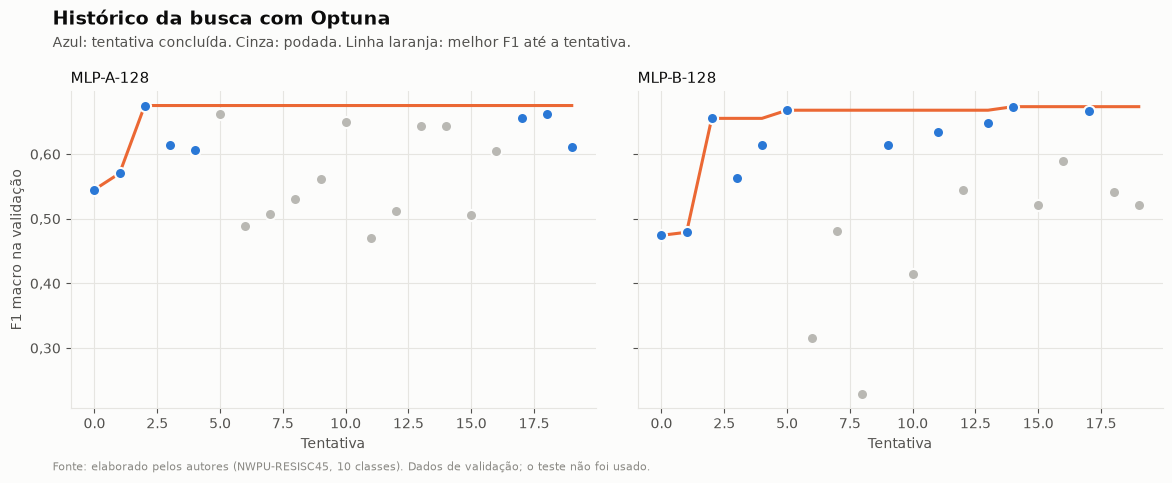

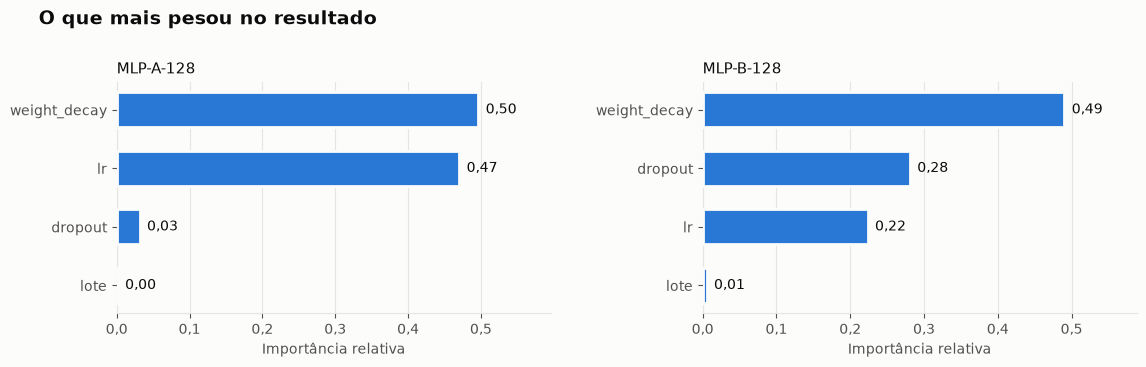

In [18]:
from matplotlib.ticker import FuncFormatter


def graficos_optuna(estudos, saida):
    virgula2 = FuncFormatter(lambda v, _: f"{v:.2f}".replace(".", ","))
    virgula1 = FuncFormatter(lambda v, _: f"{v:.1f}".replace(".", ","))
    SUP, TINTA, TINTA_2, GRADE = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
    AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#b9b8b3"
    plt.rcParams.update({"font.family": "DejaVu Sans", "axes.facecolor": SUP, "figure.facecolor": SUP, "savefig.facecolor": SUP,
                         "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRADE, "axes.grid": True,
                         "grid.color": GRADE, "axes.axisbelow": True, "text.color": TINTA, "axes.labelcolor": TINTA_2,
                         "xtick.color": TINTA_2, "ytick.color": TINTA_2})
    saida.mkdir(parents=True, exist_ok=True)

    fig, eixos = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
    for ax, (arq, estudo) in zip(eixos, estudos.items()):
        ts = [t for t in estudo.trials if t.state.name in ("COMPLETE", "PRUNED")]
        for t in ts:
            ok = t.state.name == "COMPLETE"
            v = t.value if ok else max((x for x in t.intermediate_values.values()), default=None)
            if v is not None:
                ax.plot([t.number], [v], "o", color=AZUL if ok else CINZA, markersize=8, markeredgecolor=SUP, markeredgewidth=1.5, zorder=3)
        melhor, acumulado = -1, []
        for t in sorted(ts, key=lambda x: x.number):
            if t.state.name == "COMPLETE":
                melhor = max(melhor, t.value)
            acumulado.append((t.number, melhor if melhor > 0 else None))
        ax.plot([n for n, v in acumulado if v], [v for n, v in acumulado if v], color=LARANJA, lw=2.2, zorder=2)
        ax.set_title(f"MLP-{arq}-128", loc="left", fontsize=11, color=TINTA)
        ax.set_xlabel("Tentativa"); ax.yaxis.set_major_formatter(virgula2)
    eixos[0].set_ylabel("F1 macro na validação")
    fig.text(0.055, 0.97, "Histórico da busca com Optuna", fontsize=14, fontweight="bold", ha="left", va="top")
    fig.text(0.055, 0.915, "Azul: tentativa concluída. Cinza: podada. Linha laranja: melhor F1 até a tentativa.", fontsize=10, color=TINTA_2, ha="left", va="top")
    fig.text(0.055, 0.01, "Fonte: elaborado pelos autores (NWPU-RESISC45, 10 classes). Dados de validação; o teste não foi usado.", fontsize=8, color="#8a8984")
    fig.subplots_adjust(left=0.07, right=0.98, top=0.8, bottom=0.14, wspace=0.08)
    fig.savefig(saida / "optuna_historico.png", dpi=200); plt.show()

    fig, eixos = plt.subplots(1, 2, figsize=(12, 3.8))
    algum = False
    for ax, (arq, estudo) in zip(eixos, estudos.items()):
        try:
            imp = optuna.importance.get_param_importances(estudo)
        except Exception:
            ax.set_title(f"MLP-{arq}-128: poucas tentativas para estimar", loc="left", fontsize=10, color=TINTA_2); ax.axis("off"); continue
        algum = True
        nomes, valores = list(imp.keys())[::-1], list(imp.values())[::-1]
        ax.barh(nomes, valores, color=AZUL, edgecolor=SUP, linewidth=2, height=0.6, zorder=3)
        for y, v in enumerate(valores):
            ax.text(v + 0.01, y, f"{v:.2f}".replace(".", ","), va="center", fontsize=10, color=TINTA)
        ax.set_xlim(0, max(valores) * 1.2); ax.set_title(f"MLP-{arq}-128", loc="left", fontsize=11, color=TINTA)
        ax.set_xlabel("Importância relativa"); ax.grid(axis="y", visible=False); ax.xaxis.set_major_formatter(virgula1)
    fig.text(0.055, 0.97, "O que mais pesou no resultado", fontsize=14, fontweight="bold", ha="left", va="top")
    fig.subplots_adjust(left=0.12, right=0.97, top=0.78, bottom=0.17, wspace=0.35)
    if algum:
        fig.savefig(saida / "optuna_importancia.png", dpi=200)
    plt.show()


graficos_optuna(estudos, RAIZ / "resultados" / "figuras" / "mlp")

## 13. Retreino das seis MLPs com os melhores hiperparâmetros

Cada MLP usa os melhores hiperparâmetros do **seu** estudo (`lr`, `weight_decay`, `dropout` e `lote`), nas três receitas de aumento de dados (nenhum, leve e forte). Assim, a única diferença entre as três continua sendo o aumento.

- Limite de 200 épocas e paciência 10, como nos treinos anteriores.
- Os nomes terminam em `_opt`: `MLP-A-128_opt`, `MLP-A-128_aug_opt`, `MLP-A-128_aug2_opt` e os equivalentes da MLP-B. **Os treinos anteriores não são tocados.** A função confere isso e para se algum nome coincidir com um deles.
- Os arquivos novos entram em `modelos/`, `resultados/historicos/`, `resultados/configs/` e `resultados/experimentos.csv` (como linhas novas, com `tipo_execucao = preliminar_optuna`).

In [19]:
RECEITAS_OPT = [("", False, "sem aumento"), ("_aug", True, "aumento leve"), ("_aug2", "forte", "aumento forte")]
resultados_opt = {}
for arq, Modelo in (("A", MLPA_HP), ("B", MLPB_HP)):
    hp = melhores[arq]
    for sufixo, aumento, rotulo in RECEITAS_OPT:
        nome = f"MLP-{arq}-128{sufixo}_opt"
        print(f"##### {nome} ({rotulo}) | lr {hp['lr']:.2e}  weight_decay {hp['weight_decay']:.2e}  dropout {hp['dropout']}  lote {hp['lote']}")
        fixar_semente()
        resultados_opt[(arq, sufixo)] = treinar_hp(Modelo(hp["dropout"]), nome, aumento, hp["lr"], hp["weight_decay"],
                                                  hp["lote"], MAX_EPOCAS, extras={"busca": "optuna", "dropout": hp["dropout"], "estudo": f"MLP-{arq}-128"})

##### MLP-A-128_opt (sem aumento) | lr 1.15e-03  weight_decay 7.07e-06  dropout 0.3  lote 128
[MLP-A-128_opt_preliminar] época   1/200 | treino: perda 1.7910 acc 0.3601 P 0.3185 R 0.3600 F1 0.3110 | val: perda 1.5587 acc 0.4581 P 0.4523 R 0.4581 F1 0.4002 |   2.2s  *checkpoint*
[MLP-A-128_opt_preliminar] época   2/200 | treino: perda 1.4895 acc 0.4858 P 0.4595 R 0.4858 F1 0.4630 | val: perda 1.3803 acc 0.5362 P 0.5265 R 0.5362 F1 0.4986 |   1.9s  *checkpoint*
[MLP-A-128_opt_preliminar] época   3/200 | treino: perda 1.3314 acc 0.5462 P 0.5272 R 0.5462 F1 0.5308 | val: perda 1.2892 acc 0.5657 P 0.5406 R 0.5657 F1 0.5421 |   2.4s  *checkpoint*
[MLP-A-128_opt_preliminar] época   4/200 | treino: perda 1.1959 acc 0.5893 P 0.5762 R 0.5892 F1 0.5789 | val: perda 1.2821 acc 0.5610 P 0.5520 R 0.5610 F1 0.5352 |   2.0s
[MLP-A-128_opt_preliminar] época   5/200 | treino: perda 1.1187 acc 0.6120 P 0.5977 R 0.6119 F1 0.6006 | val: perda 1.2811 acc 0.5524 P 0.5580 R 0.5524 F1 0.5428 |   2.3s  *checkpo

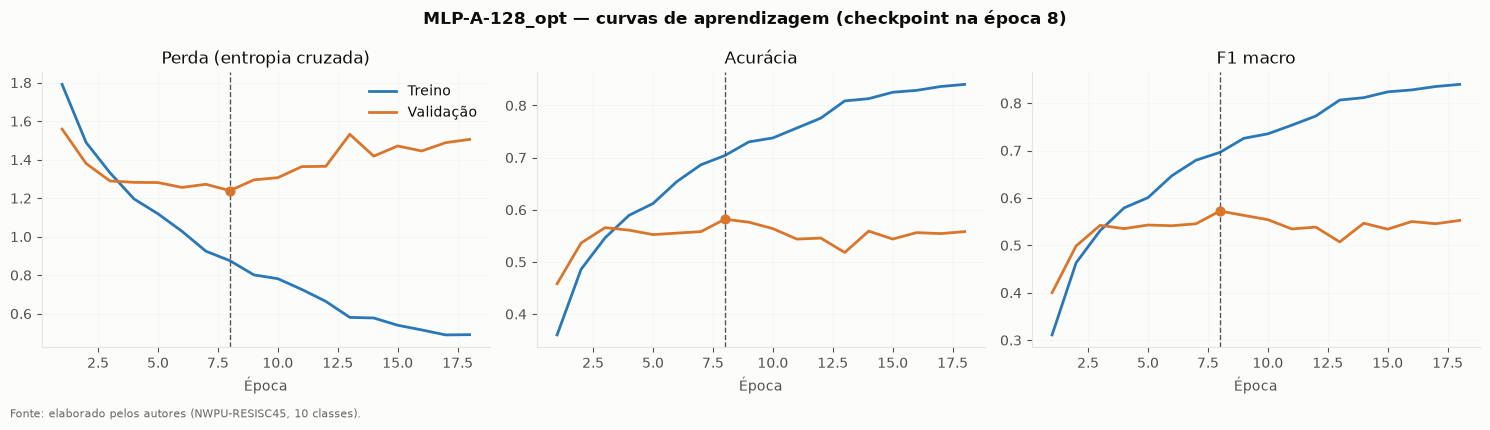

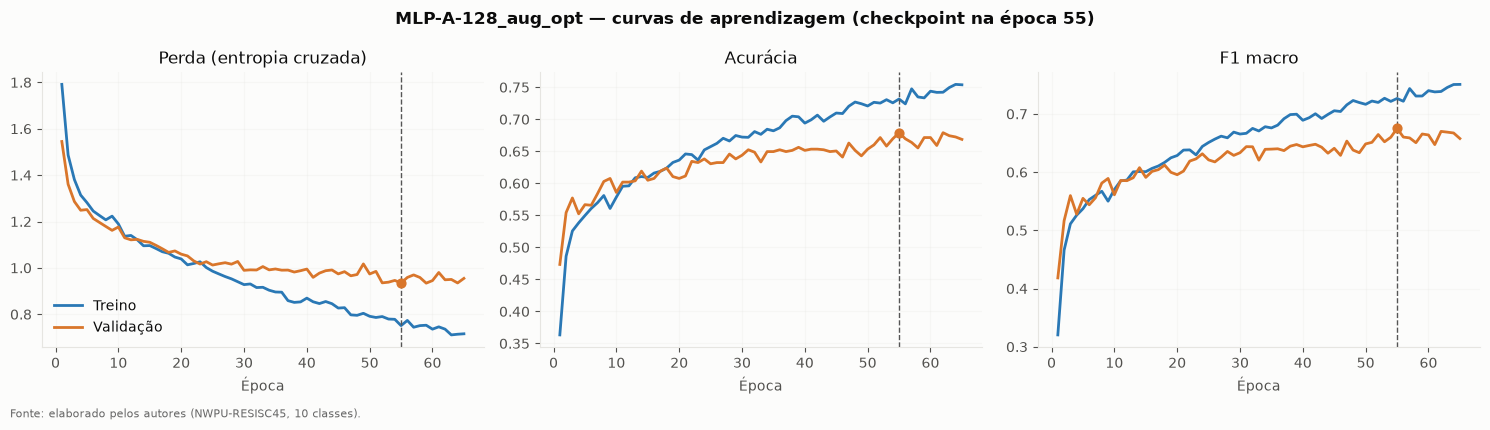

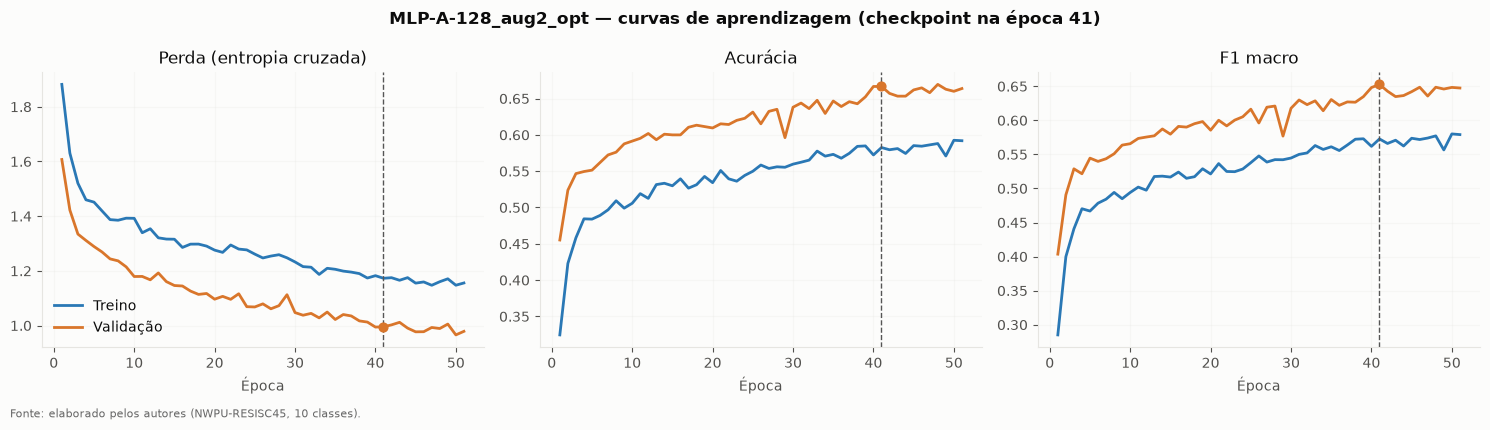

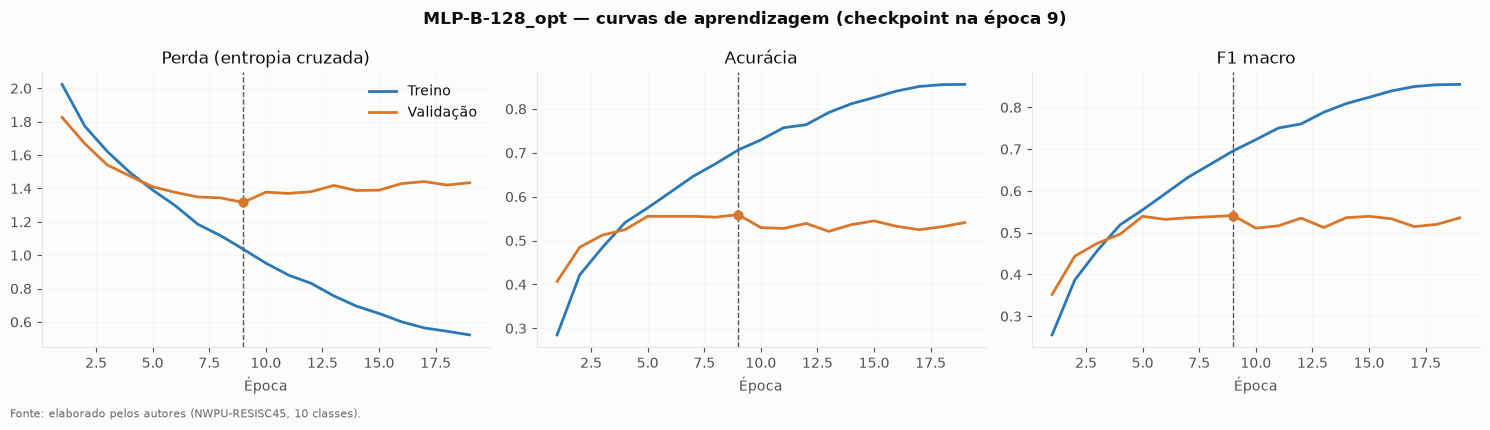

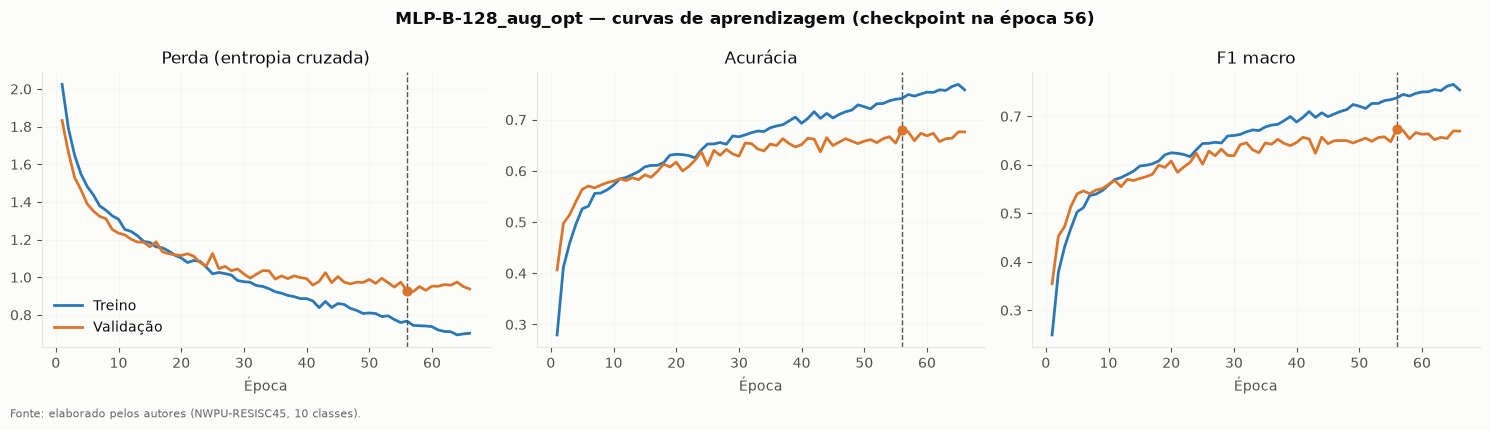

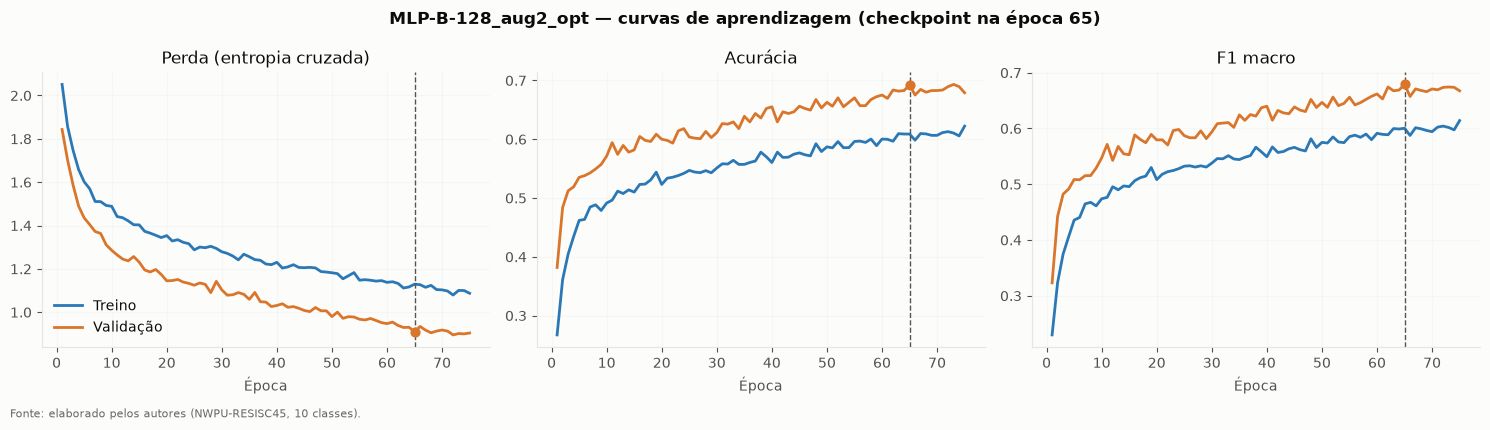

In [20]:
for (arq, sufixo), (resumo, hist) in resultados_opt.items():
    plotar_curvas(hist, f"MLP-{arq}-128{sufixo}_opt")

## 14. Antes × depois do Optuna

Compara cada MLP com a mesma receita de aumento, nos treinos anteriores (hiperparâmetros fixos: lr 1e-4, weight decay 1e-4, dropout 0,5 e lote 64) e nos novos (hiperparâmetros do Optuna). `dif_f1_treino_val` é o F1 de treino menos o de validação no melhor ponto.

In [21]:
exp_csv = pd.read_csv(RAIZ / "resultados" / "experimentos.csv").set_index("nome_execucao")
linhas = []
for arq in "AB":
    for sufixo, _, rotulo in RECEITAS_OPT:
        antes, depois = f"MLP-{arq}-128{sufixo}_preliminar", f"MLP-{arq}-128{sufixo}_opt_preliminar"
        dif = {}
        for chave, n in (("antes", antes), ("depois", depois)):
            h = pd.read_csv(RAIZ / "resultados" / "historicos" / f"{n}_historico.csv")
            ck = h[h["checkpoint"]].iloc[0]
            dif[chave] = round(ck["f1_macro_treino"] - ck["f1_macro_validacao"], 3)
        linhas.append({"MLP": f"MLP-{arq}-128", "receita": rotulo,
                       "F1 val antes": exp_csv.loc[antes, "f1_macro_validacao"], "F1 val Optuna": exp_csv.loc[depois, "f1_macro_validacao"],
                       "ganho": round(exp_csv.loc[depois, "f1_macro_validacao"] - exp_csv.loc[antes, "f1_macro_validacao"], 4),
                       "dif_f1_treino_val antes": dif["antes"], "dif_f1_treino_val Optuna": dif["depois"],
                       "épocas antes": exp_csv.loc[antes, "epocas_executadas"], "épocas Optuna": exp_csv.loc[depois, "epocas_executadas"],
                       "tempo antes (s)": exp_csv.loc[antes, "tempo_total_s"], "tempo Optuna (s)": exp_csv.loc[depois, "tempo_total_s"]})
comparacao_opt = pd.DataFrame(linhas).set_index(["MLP", "receita"])
print(comparacao_opt.to_string())
comparacao_opt

                         F1 val antes  F1 val Optuna   ganho  dif_f1_treino_val antes  dif_f1_treino_val Optuna  épocas antes  épocas Optuna  tempo antes (s)  tempo Optuna (s)
MLP       receita                                                                                                                                                              
MLP-A-128 sem aumento          0.5359         0.5723  0.0364                    0.217                     0.124            29             18             53.6              36.6
          aumento leve         0.6363         0.6751  0.0388                    0.010                     0.051            75             65            181.2             108.2
          aumento forte        0.5900         0.6528  0.0628                   -0.109                    -0.080            34             51            127.7             134.0
MLP-B-128 sem aumento          0.5353         0.5410  0.0057                    0.124                     0.155         

F1 val antes  F1 val Optuna   ganho  \
MLP       receita                                              
MLP-A-128 sem aumento          0.5359         0.5723  0.0364   
          aumento leve         0.6363         0.6751  0.0388   
          aumento forte        0.5900         0.6528  0.0628   
MLP-B-128 sem aumento          0.5353         0.5410  0.0057   
          aumento leve         0.5980         0.6734  0.0754   
          aumento forte        0.5726         0.6791  0.1065   

                         dif_f1_treino_val antes  dif_f1_treino_val Optuna  \
MLP       receita                                                            
MLP-A-128 sem aumento                      0.217                     0.124   
          aumento leve                     0.010                     0.051   
          aumento forte                   -0.109                    -0.080   
MLP-B-128 sem aumento                      0.124                     0.155   
          aumento leve                    -0.027                     0.065   
          aumento forte                   -0.103                    -0.079   

                         épocas antes  épocas Optuna  tempo antes (s)  \
MLP       receita                                                       
MLP-A-128 sem aumento              29             18             53.6   
          aumento leve             75             65            181.2   
          aumento forte            34             51            127.7   
MLP-B-128 sem aumento              51             19             99.5   
          aumento leve             90             66            224.0   
          aumento forte            78             75            348.5   

                         tempo Optuna (s)  
MLP       receita                          
MLP-A-128 sem aumento                36.6  
          aumento leve              108.2  
          aumento forte             134.0  
MLP-B-128 sem aumento                26.9  
          aumento leve              113.6  
          aumento forte             219.8

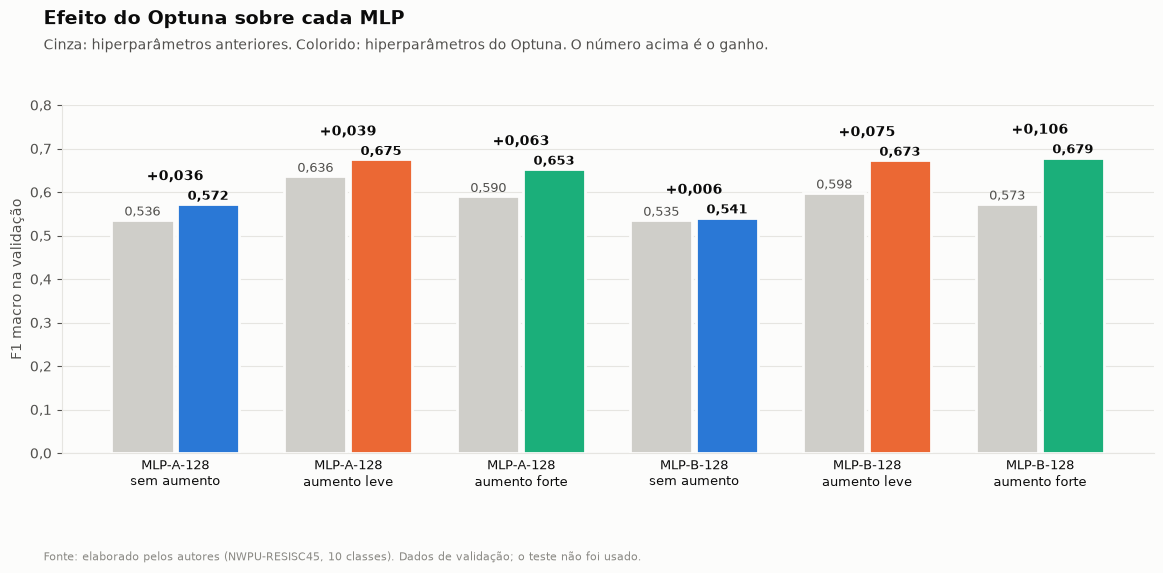

In [22]:
from matplotlib.ticker import FuncFormatter


def grafico_antes_depois(comp, saida):
    virgula1 = FuncFormatter(lambda v, _: f"{v:.1f}".replace(".", ","))
    SUP, TINTA, TINTA_2, GRADE = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
    CORES = {"sem aumento": "#2a78d6", "aumento leve": "#eb6834", "aumento forte": "#1baf7a"}
    ANTES = "#cfcec9"
    plt.rcParams.update({"font.family": "DejaVu Sans", "axes.facecolor": SUP, "figure.facecolor": SUP, "savefig.facecolor": SUP,
                         "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRADE, "axes.grid": True,
                         "grid.color": GRADE, "axes.axisbelow": True, "text.color": TINTA, "axes.labelcolor": TINTA_2,
                         "xtick.color": TINTA_2, "ytick.color": TINTA_2})
    fig, ax = plt.subplots(figsize=(12, 5.8))
    fig.subplots_adjust(left=0.07, right=0.98, top=0.8, bottom=0.2)
    larg = 0.36
    for i, ((arq, rot), linha) in enumerate(comp.iterrows()):
        a, d = linha["F1 val antes"], linha["F1 val Optuna"]
        ax.bar(i - larg / 2 - 0.01, a, width=larg, color=ANTES, edgecolor=SUP, linewidth=2, zorder=3)
        ax.bar(i + larg / 2 + 0.01, d, width=larg, color=CORES[rot], edgecolor=SUP, linewidth=2, zorder=3)
        ax.text(i - larg / 2 - 0.01, a + 0.01, f"{a:.3f}".replace(".", ","), ha="center", fontsize=9, color=TINTA_2)
        ax.text(i + larg / 2 + 0.01, d + 0.01, f"{d:.3f}".replace(".", ","), ha="center", fontsize=9.5, fontweight="bold", color=TINTA)
        ganho = linha["ganho"]
        ax.text(i, max(a, d) + 0.055, f"{'+' if ganho >= 0 else '−'}{abs(ganho):.3f}".replace(".", ","), ha="center", fontsize=10, fontweight="bold", color=TINTA)
    ax.set_xticks(range(len(comp)))
    ax.set_xticklabels([f"{arq}\n{rot}" for arq, rot in comp.index], fontsize=9.5, color=TINTA)
    ax.set_ylim(0, 0.8); ax.set_ylabel("F1 macro na validação"); ax.yaxis.set_major_formatter(virgula1); ax.grid(axis="x", visible=False); ax.tick_params(axis="x", length=0)
    fig.text(0.055, 0.965, "Efeito do Optuna sobre cada MLP", fontsize=14, fontweight="bold", ha="left", va="top")
    fig.text(0.055, 0.915, "Cinza: hiperparâmetros anteriores. Colorido: hiperparâmetros do Optuna. O número acima é o ganho.", fontsize=10, color=TINTA_2, ha="left", va="top")
    fig.text(0.055, 0.015, "Fonte: elaborado pelos autores (NWPU-RESISC45, 10 classes). Dados de validação; o teste não foi usado.", fontsize=8, color="#8a8984")
    saida.mkdir(parents=True, exist_ok=True)
    fig.savefig(saida / "comparacao_6_optuna_antes_depois.png", dpi=200); plt.show()


grafico_antes_depois(comparacao_opt, RAIZ / "resultados" / "figuras" / "mlp")

## 15. Leitura dos resultados do Optuna (preencher após rodar)

- Melhores hiperparâmetros de cada MLP (`lr`, `weight_decay`, `dropout`, `lote`) e como eles diferem dos anteriores: …
- O Optuna melhorou o F1 de validação? Em quais receitas? …
- O que mais pesou na busca (gráfico de importância)? …
- A diferença entre treino e validação mudou? …
- Custo da busca: número de tentativas, podadas e tempo total: …
- Cuidado: a busca foi feita com aumento leve. As receitas sem aumento e com aumento forte usam os mesmos hiperparâmetros, que podem não ser os ideais para elas. …